In [1]:
# ============================================================
# CELL 0: Configuration, seeds, environment
# ============================================================
import os
# Reduce CUDA memory fragmentation (must be set before torch initializes its
# CUDA caching allocator, so this line stays first, before `import torch`).
os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

import random
import numpy as np
import torch
import torch._utils  # noqa: F401
# Kaggle-environment fix (preserved from the working notebook): some
# torch/torchvision builds don't have `torch._utils` bound as an attribute of
# `torch` yet at this point, which makes `from torchvision import transforms`
# (Cell 2+) fail with "AttributeError: module 'torch' has no attribute
# '_utils'". This import must run before any torchvision import.

import torch.multiprocessing as _mp
try:
    # Prefer "fork" so DataLoader worker processes inherit this process's
    # already-fixed `torch` module instead of re-importing it from scratch.
    _mp.set_start_method("fork", force=True)
except RuntimeError:
    pass  # start method already set for this kernel session; safe to ignore

# ============================================================
# CONFIGURATION
# ============================================================
CONFIG = {
    # ---- Data ----
    "data_root": "/kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23",
    "seed": 42,
    "max_videos_to_use": None,   # e.g. 500 for a quick debug run, None = use all

    # ---- Temporal sampling ----
    "seq_len": 16,                 # frames actually fed to the model per video
    "frame_pool_size": 32,         # frames extracted per video to disk, so train-time
                                    # temporal sampling has room to vary between epochs
                                    # (val/test always sample deterministically from this pool)
    "img_size": 224,

    # ---- Batching ----
    "batch_size": 8,
    "adv_train_batch_size_fallback": 4,   # drop to this if CUDA OOM persists
    "num_workers": 0,   # Kaggle-environment fix (preserved): DataLoader worker
                         # processes on this image hit the same torch._utils
                         # AttributeError independently; 0 avoids subprocesses entirely.

    # ---- Splits ----
    "test_split": 0.15,
    "val_split": 0.15,

    # ---- Social-media compression augmentation (configurable, moderate) ----
    "compression_prob": 0.5,
    "compression_downscale_range": (0.7, 1.0),
    "compression_jpeg_quality_range": (30, 70),   # was an extreme (10,25) previously
    "compression_blur_prob": 0.3,
    "compression_blur_kernel": 3,

    # ---- Spatial augmentation (configurable, moderate -- preserves forensic artifacts) ----
    "aug_flip_prob": 0.5,
    "aug_rotation_range": (-10.0, 10.0),
    "aug_brightness_range": (0.9, 1.1),
    "aug_contrast_range": (0.9, 1.1),
    "aug_saturation_range": (0.95, 1.05),
    "aug_hue_range": (-0.02, 0.02),
    "aug_crop_padding": 4,
    "aug_noise_prob": 0.2,
    "aug_noise_std": 0.01,   # additive Gaussian noise on the normalized tensor

    # ---- Model architecture ----
    "lstm_hidden_size": 512,
    "lstm_num_layers": 2,
    "lstm_bidirectional": True,
    "dropout": 0.4,
    "use_temporal_attention": True,   # False = fall back to mean pooling

    # ---- Staged transfer learning ----
    "phase1_epochs": 3,          # backbone frozen: train temporal head + classifier only
    "phase2_epochs": 4,          # unfreeze last backbone blocks, fine-tune end-to-end
    "unfreeze_last_n_blocks": 3, # how many trailing EfficientNet-B1 blocks to unfreeze in phase 2
    "backbone_lr": 1e-5,         # discriminative LR: backbone (phase 2 only)
    "head_lr": 1e-4,             # discriminative LR: projection/LSTM/attention/classifier

    # ---- Optimization ----
    "weight_decay": 1e-2,
    "grad_clip_norm": 5.0,
    "scheduler_factor": 0.5,
    "scheduler_patience": 2,
    "early_stopping_patience": 4,   # epochs of no val-F1 improvement before stopping

    # ---- Loss ----
    "use_class_weight": True,    # pos_weight computed from TRAIN labels only
    "use_focal_loss": False,     # optional; kept off by default (BCE is well justified here)
    "focal_gamma": 2.0,

    # ---- Adversarial Robustness Training (ART) ----
    "adv_training": True,
    "adv_method": "FGSM",        # attack used DURING training (fast, practical on Kaggle GPU)
    "epsilon": 4 / 255,          # perturbation budget in PIXEL space
    "adv_alpha": 1 / 255,        # PGD step size in PIXEL space (evaluation only)
    "adv_steps": 3,
    "adv_loss_weight": 0.5,
    "clean_loss_weight": 0.5,
    "adv_eval_epsilon": 4 / 255,

    # ---- Threshold selection (validation set ONLY) ----
    "threshold_search_min": 0.30,
    "threshold_search_max": 0.70,
    "threshold_search_step": 0.01,

    # ---- Checkpoints / artifacts ----
    "save_clean_checkpoint": "/kaggle/working/best_clean_model.pth",
    "save_art_checkpoint": "/kaggle/working/best_art_model.pth",
    "save_run_config_path": "/kaggle/working/run_config.json",
    "save_best_metrics_path": "/kaggle/working/best_metrics.json",

    # ---- Ablation study (optional, off by default -- Kaggle runtime is limited) ----
    "run_ablation": False,
    "ablation_epochs": 2,

    # ---- System ----
    "device": torch.device("cuda" if torch.cuda.is_available() else "cpu"),
}


def set_global_seed(seed):
    """Seeds python `random`, numpy, and torch (CPU + all CUDA devices)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_global_seed(CONFIG["seed"])

print("=" * 60)
print("CONFIGURATION SUMMARY")
print("=" * 60)
print(f"Device                 : {CONFIG['device']}")
print(f"Seed                   : {CONFIG['seed']}")
print(f"seq_len / frame_pool    : {CONFIG['seq_len']} / {CONFIG['frame_pool_size']}")
print(f"img_size / batch_size   : {CONFIG['img_size']} / {CONFIG['batch_size']}")
print(f"Phase1/Phase2 epochs    : {CONFIG['phase1_epochs']} / {CONFIG['phase2_epochs']}")
print(f"backbone_lr / head_lr   : {CONFIG['backbone_lr']} / {CONFIG['head_lr']}")
print(f"LSTM hidden/layers/bidir: {CONFIG['lstm_hidden_size']} / {CONFIG['lstm_num_layers']} / {CONFIG['lstm_bidirectional']}")
print(f"Temporal attention      : {CONFIG['use_temporal_attention']}")
print(f"Class weighting (BCE)   : {CONFIG['use_class_weight']}")
print(f"ART: method/epsilon/w   : {CONFIG['adv_method']} / {CONFIG['epsilon']:.4f} / {CONFIG['adv_loss_weight']}")
print(f"Ablation study enabled  : {CONFIG['run_ablation']}")
print("=" * 60)
print("NOTE on reproducibility: cuDNN's fused RNN (LSTM) backward kernel is not")
print("bit-exact deterministic even with cudnn.deterministic=True (a known")
print("PyTorch/cuDNN limitation) -- results should be closely but not exactly")
print("reproducible run-to-run.")


CONFIGURATION SUMMARY
Device                 : cuda
Seed                   : 42
seq_len / frame_pool    : 16 / 32
img_size / batch_size   : 224 / 8
Phase1/Phase2 epochs    : 3 / 4
backbone_lr / head_lr   : 1e-05 / 0.0001
LSTM hidden/layers/bidir: 512 / 2 / True
Temporal attention      : True
Class weighting (BCE)   : True
ART: method/epsilon/w   : FGSM / 0.0157 / 0.5
Ablation study enabled  : False
NOTE on reproducibility: cuDNN's fused RNN (LSTM) backward kernel is not
bit-exact deterministic even with cudnn.deterministic=True (a known
PyTorch/cuDNN limitation) -- results should be closely but not exactly
reproducible run-to-run.


In [2]:
# ============================================================
# CELL 1: Imports and utility functions
# ============================================================
if "CONFIG" not in globals():
    raise RuntimeError(
        "CONFIG is not defined. You must run Cell 0 (Configuration, seeds, "
        "environment) BEFORE this cell -- this is required again after any "
        "kernel restart. Please re-run the notebook from Cell 0 onward."
    )

import os
import gc
import json
import random
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.nn.functional as Fn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.utils import make_grid
from torchvision.models import efficientnet_b1, EfficientNet_B1_Weights
import torchvision.transforms.functional as TF

from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, balanced_accuracy_score, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve,
)

from tqdm.notebook import tqdm

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

USE_AMP = (CONFIG["device"].type == "cuda")


def set_seed(seed):
    """Re-seeds python/numpy/torch -- used again before each ablation run so
    every experiment starts from an identical RNG state (mirrors Cell 0)."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def free_cuda_memory():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def unnormalize_frame(tensor_frame):
    """[3, H, W] normalized tensor -> [H, W, 3] numpy image in [0, 1]."""
    mean = np.array(IMAGENET_MEAN)
    std = np.array(IMAGENET_STD)
    img = tensor_frame.detach().cpu().numpy().transpose(1, 2, 0)
    return np.clip(std * img + mean, 0, 1)


def compute_metrics(labels, probs, threshold=0.5):
    """Full metric suite used across the notebook. `labels` are ints (0/1),
    `probs` are the sigmoid outputs (fake probability) in [0, 1]."""
    labels = np.asarray(labels).astype(int)
    probs = np.asarray(probs)
    preds = (probs >= threshold).astype(int)

    try:
        roc_auc = roc_auc_score(labels, probs)
    except ValueError:
        roc_auc = 0.0
    try:
        pr_auc = average_precision_score(labels, probs)
    except ValueError:
        pr_auc = 0.0

    return {
        "threshold": threshold,
        "accuracy": accuracy_score(labels, preds),
        "precision": precision_score(labels, preds, average="macro", zero_division=0),
        "recall": recall_score(labels, preds, average="macro", zero_division=0),
        "f1": f1_score(labels, preds, average="macro", zero_division=0),
        "precision_fake": precision_score(labels, preds, pos_label=1, zero_division=0),
        "recall_fake": recall_score(labels, preds, pos_label=1, zero_division=0),
        "f1_fake": f1_score(labels, preds, pos_label=1, zero_division=0),
        "precision_real": precision_score(labels, preds, pos_label=0, zero_division=0),
        "recall_real": recall_score(labels, preds, pos_label=0, zero_division=0),
        "f1_real": f1_score(labels, preds, pos_label=0, zero_division=0),
        "roc_auc": roc_auc,
        "pr_auc": pr_auc,
        "balanced_accuracy": balanced_accuracy_score(labels, preds),
    }


def print_metrics(tag, m):
    print(f"[{tag}] thr={m['threshold']:.3f}  "
          f"Acc={m['accuracy']:.4f}  F1={m['f1']:.4f}  "
          f"ROC-AUC={m['roc_auc']:.4f}  PR-AUC={m['pr_auc']:.4f}  "
          f"BalAcc={m['balanced_accuracy']:.4f}")


print("Imports and utility functions ready.")


Imports and utility functions ready.


In [3]:
# ============================================================
# CELL 2: Dataset discovery and video extraction
# ============================================================
# Extracts `frame_pool_size` frames per video (uniformly spread across the
# full video, via np.linspace over the frame count) to local Kaggle scratch
# disk as JPEGs. Extracting MORE frames than `seq_len` (rather than exactly
# seq_len, as before) is what gives Cell 4's temporal sampling room to vary
# between epochs during training while still sampling deterministically for
# validation/test.

def discover_videos(data_root, max_videos=None):
    root_path = Path(data_root)
    real_folders = ["original", "Original", "real"]
    fake_folders = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures", "FaceShifter"]

    real_videos, fake_videos = [], []
    for rf in real_folders:
        r_path = root_path / rf
        if r_path.exists():
            real_videos.extend(list(r_path.glob("*.mp4")) + list(r_path.glob("*/*.mp4")))

    for ff in fake_folders:
        f_path = root_path / ff
        if f_path.exists():
            fake_videos.extend(list(f_path.glob("*.mp4")) + list(f_path.glob("*/*.mp4")))

    if max_videos is not None:
        half_limit = max_videos // 2
        real_videos = real_videos[:half_limit]
        fake_videos = fake_videos[:half_limit]

    print(f"Discovered {len(real_videos)} real videos and {len(fake_videos)} fake videos "
          f"under {data_root}")
    return real_videos, fake_videos


def extract_videos_to_disk(data_root, output_dir="/kaggle/working/extracted_frames",
                            max_videos=None, frame_pool_size=32):
    """One-time pre-processor: unpacks MP4 videos into `frame_pool_size`
    static JPEG frames each, uniformly spread across the video's duration."""
    out_path = Path(output_dir)
    out_path.mkdir(parents=True, exist_ok=True)

    real_videos, fake_videos = discover_videos(data_root, max_videos)

    records = []
    all_tasks = [(p, 0) for p in real_videos] + [(p, 1) for p in fake_videos]

    print(f"Pre-extracting {len(all_tasks)} videos to disk "
          f"({frame_pool_size} frames/video; this runs only once)...")

    for v_path_str, label in tqdm(all_tasks, desc="Extracting Frames"):
        v_path = Path(v_path_str)
        vid_out_dir = out_path / ("real" if label == 0 else "fake") / v_path.stem
        vid_out_dir.mkdir(parents=True, exist_ok=True)

        existing_frames = list(vid_out_dir.glob("*.jpg"))
        if len(existing_frames) >= min(frame_pool_size, CONFIG["seq_len"]):
            records.append((str(vid_out_dir), label))
            continue

        cap = cv2.VideoCapture(str(v_path))
        total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        if total_frames >= frame_pool_size:
            indices = np.linspace(0, total_frames - 1, frame_pool_size, dtype=int)
        else:
            indices = np.arange(max(total_frames, 1))

        curr_frame = 0
        target_indices = set(int(i) for i in indices)
        saved_count = 0

        while cap.isOpened() and saved_count < len(target_indices):
            ret, frame = cap.read()
            if not ret:
                break
            if curr_frame in target_indices:
                frame_path = vid_out_dir / f"frame_{saved_count:03d}.jpg"
                cv2.imwrite(str(frame_path), frame)
                saved_count += 1
            curr_frame += 1
        cap.release()

        if saved_count > 0:
            records.append((str(vid_out_dir), label))

    return records


extracted_records = extract_videos_to_disk(
    CONFIG["data_root"],
    output_dir="/kaggle/working/extracted_frames",
    max_videos=CONFIG["max_videos_to_use"],
    frame_pool_size=CONFIG["frame_pool_size"],
)

if len(extracted_records) == 0:
    raise ValueError("No frames were extracted. Check your CONFIG['data_root'] path.")

n_real = sum(1 for _, l in extracted_records if l == 0)
n_fake = sum(1 for _, l in extracted_records if l == 1)
print(f"Extraction complete. Total usable videos: {len(extracted_records)} "
      f"(real={n_real}, fake={n_fake})")


Discovered 1000 real videos and 5000 fake videos under /kaggle/input/datasets/xdxd003/ff-c23/FaceForensics++_C23
Pre-extracting 6000 videos to disk (32 frames/video; this runs only once)...


Extracting Frames:   0%|          | 0/6000 [00:00<?, ?it/s]

Extraction complete. Total usable videos: 6000 (real=1000, fake=5000)


In [4]:
# ============================================================
# CELL 3: Group-aware train/validation/test splitting
# ============================================================
# Videos are grouped by source identity (first token of the filename stem,
# FF++'s naming convention groups a real/manipulated pair under a shared id)
# so that related videos never appear across more than one split. All
# splitting/balancing uses ONLY the split's own labels -- no split is used to
# tune, threshold-select, or select a model for another split.

def get_group_id(record):
    return Path(record[0]).stem.split('_')[0]


groups = [get_group_id(r) for r in extracted_records]
labels_all = [r[1] for r in extracted_records]

# ---- Split off TEST first (touched only in evaluation cells) ----
gss_test = GroupShuffleSplit(n_splits=1, test_size=CONFIG["test_split"], random_state=CONFIG["seed"])
train_val_idx, test_idx = next(gss_test.split(extracted_records, labels_all, groups=groups))

train_val_records = [extracted_records[i] for i in train_val_idx]
test_records_raw = [extracted_records[i] for i in test_idx]
train_val_groups = [groups[i] for i in train_val_idx]
train_val_labels = [labels_all[i] for i in train_val_idx]

# ---- Split remaining into TRAIN / VAL ----
val_ratio_adjusted = CONFIG["val_split"] / (1.0 - CONFIG["test_split"])
gss_val = GroupShuffleSplit(n_splits=1, test_size=val_ratio_adjusted, random_state=CONFIG["seed"])
train_idx, val_idx = next(gss_val.split(train_val_records, train_val_labels, groups=train_val_groups))

train_records = [train_val_records[i] for i in train_idx]
val_records_raw = [train_val_records[i] for i in val_idx]
train_groups = [train_val_groups[i] for i in train_idx]
val_groups_raw = [train_val_groups[i] for i in val_idx]
test_groups_raw = [groups[i] for i in test_idx]


def balance_split(records, seed):
    """Undersamples the majority class within a split so evaluation metrics
    are computed on a class-balanced set. Uses ONLY that split's own labels."""
    real = [r for r in records if r[1] == 0]
    fake = [r for r in records if r[1] == 1]
    n = min(len(real), len(fake))
    rng = random.Random(seed)
    rng.shuffle(real)
    rng.shuffle(fake)
    balanced = real[:n] + fake[:n]
    rng.shuffle(balanced)
    return balanced


val_records = balance_split(val_records_raw, CONFIG["seed"])
test_records = balance_split(test_records_raw, CONFIG["seed"])

val_groups = [get_group_id(r) for r in val_records]
test_groups = [get_group_id(r) for r in test_records]


def split_report(name, records, grps):
    n_real = sum(1 for _, l in records if l == 0)
    n_fake = sum(1 for _, l in records if l == 1)
    print(f"{name:<6}: {len(records):5d} videos  |  real={n_real:5d}  fake={n_fake:5d}  "
          f"|  unique groups={len(set(grps)):5d}")


print("=" * 60)
print("GROUP-AWARE SPLIT REPORT")
print("=" * 60)
split_report("Train", train_records, train_groups)
split_report("Val", val_records, val_groups)
split_report("Test", test_records, test_groups)

train_group_set = set(train_groups)
val_group_set = set(val_groups_raw)   # check against the FULL (pre-balance) val groups
test_group_set = set(test_groups_raw)  # and FULL (pre-balance) test groups

overlap_train_val = train_group_set & val_group_set
overlap_train_test = train_group_set & test_group_set
overlap_val_test = val_group_set & test_group_set

assert not overlap_train_val, f"Group leakage between train/val: {overlap_train_val}"
assert not overlap_train_test, f"Group leakage between train/test: {overlap_train_test}"
assert not overlap_val_test, f"Group leakage between val/test: {overlap_val_test}"

print("\nGroup-overlap check: PASSED -- no source-identity group appears in more than one split.")
print("=" * 60)


GROUP-AWARE SPLIT REPORT
Train :  4200 videos  |  real=  700  fake= 3500  |  unique groups=  700
Val   :   300 videos  |  real=  150  fake=  150  |  unique groups=  150
Test  :   300 videos  |  real=  150  fake=  150  |  unique groups=  150

Group-overlap check: PASSED -- no source-identity group appears in more than one split.


In [5]:
# ============================================================
# CELL 4: Improved temporal sampling and preprocessing
# ============================================================
# Temporal sampling: the frame pool for each video (frame_pool_size frames,
# extracted in Cell 2) is split into `seq_len` equal segments (TSN-style).
#   - Training:   one RANDOM frame is drawn from each segment, and this is
#                 re-rolled every call (i.e. every epoch sees a different
#                 16-frame subset), acting as temporal augmentation.
#   - Validation/Test: the segment CENTER frame is always used -- fully
#                 deterministic, so evaluation never varies run to run.
# Spatial/compression augmentation parameters are drawn once per __getitem__
# call (not per frame) so the same transform is applied consistently across
# every frame of a sampled clip.

def apply_social_media_compression(img_rgb, scale_factor, should_blur, quality):
    """Downscale -> (optional) mild blur -> JPEG re-encode -> upscale. This
    is the single, configurable implementation used everywhere in the
    notebook (the scale_factor is now correctly randomized via CONFIG's
    range instead of the fixed 1.0 that produced a no-op downscale)."""
    h, w, _ = img_rgb.shape
    new_h, new_w = max(1, int(h * scale_factor)), max(1, int(w * scale_factor))
    img_resized = cv2.resize(img_rgb, (new_w, new_h), interpolation=cv2.INTER_AREA)
    img_resized = cv2.resize(img_resized, (w, h), interpolation=cv2.INTER_LINEAR)

    if should_blur:
        k = CONFIG["compression_blur_kernel"]
        k = k if k % 2 == 1 else k + 1
        img_resized = cv2.GaussianBlur(img_resized, (k, k), 0)

    encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), quality]
    _, encimg = cv2.imencode('.jpg', img_resized, encode_param)
    decimg = cv2.imdecode(encimg, 1)
    return decimg


class PreextractedVideoDataset(Dataset):
    def __init__(self, sample_records, seq_len=16, img_size=224, is_train=True):
        self.sample_records = sample_records
        self.seq_len = seq_len
        self.img_size = img_size
        self.is_train = is_train

    def __len__(self):
        return len(self.sample_records)

    def _sample_frame_indices(self, n_available, rng):
        if n_available <= self.seq_len:
            return list(range(n_available))

        bounds = np.linspace(0, n_available, self.seq_len + 1).astype(int)
        indices = []
        for i in range(self.seq_len):
            lo, hi = int(bounds[i]), int(bounds[i + 1])
            hi = max(hi, lo + 1)
            if self.is_train:
                indices.append(rng.randint(lo, hi - 1))
            else:
                indices.append((lo + hi - 1) // 2)  # deterministic segment center
        return indices

    def __getitem__(self, idx):
        folder_path, label = self.sample_records[idx]
        folder = Path(folder_path)
        frame_files = sorted(list(folder.glob("*.jpg")))
        n_available = len(frame_files)

        # Fresh RNG each call for training (true epoch-to-epoch variation);
        # unused (but present for API symmetry) for the deterministic val/test path.
        rng = random.Random() if self.is_train else random.Random(0)

        frame_indices = self._sample_frame_indices(n_available, rng)
        selected_files = [frame_files[i] for i in frame_indices]

        # ---- Per-clip augmentation parameters (shared across all frames) ----
        should_compress = self.is_train and rng.random() < CONFIG["compression_prob"]
        compress_quality = (rng.randint(*CONFIG["compression_jpeg_quality_range"])
                             if should_compress else None)
        should_blur = should_compress and rng.random() < CONFIG["compression_blur_prob"]
        scale_factor = rng.uniform(*CONFIG["compression_downscale_range"])

        if self.is_train:
            do_flip = rng.random() < CONFIG["aug_flip_prob"]
            rotation_angle = rng.uniform(*CONFIG["aug_rotation_range"])
            brightness_factor = rng.uniform(*CONFIG["aug_brightness_range"])
            contrast_factor = rng.uniform(*CONFIG["aug_contrast_range"])
            saturation_factor = rng.uniform(*CONFIG["aug_saturation_range"])
            hue_factor = rng.uniform(*CONFIG["aug_hue_range"])
            crop_padding = CONFIG["aug_crop_padding"]
            crop_top = rng.randint(0, 2 * crop_padding)
            crop_left = rng.randint(0, 2 * crop_padding)
            add_noise = rng.random() < CONFIG["aug_noise_prob"]

        processed_frames = []
        for f_path in selected_files:
            img = cv2.imread(str(f_path))
            img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            if should_compress:
                img_rgb = apply_social_media_compression(
                    img_rgb, scale_factor, should_blur, compress_quality
                )

            pil_img = transforms.ToPILImage()(img_rgb)
            pil_img = TF.resize(pil_img, (self.img_size, self.img_size))

            if self.is_train:
                pil_img = TF.rotate(pil_img, rotation_angle)
                pil_img = TF.pad(pil_img, padding=crop_padding, padding_mode='reflect')
                pil_img = TF.crop(pil_img, top=crop_top, left=crop_left,
                                   height=self.img_size, width=self.img_size)
                if do_flip:
                    pil_img = TF.hflip(pil_img)
                pil_img = TF.adjust_brightness(pil_img, brightness_factor)
                pil_img = TF.adjust_contrast(pil_img, contrast_factor)
                pil_img = TF.adjust_hue(pil_img, hue_factor)
                pil_img = TF.adjust_saturation(pil_img, saturation_factor)

            tensor_frame = TF.to_tensor(pil_img)
            tensor_frame = TF.normalize(tensor_frame, mean=IMAGENET_MEAN, std=IMAGENET_STD)

            if self.is_train and add_noise:
                tensor_frame = tensor_frame + torch.randn_like(tensor_frame) * CONFIG["aug_noise_std"]

            processed_frames.append(tensor_frame)

        while len(processed_frames) < self.seq_len:
            if len(processed_frames) > 0:
                processed_frames.append(processed_frames[-1].clone())
            else:
                processed_frames.append(torch.zeros(3, self.img_size, self.img_size))

        video_tensor = torch.stack(processed_frames[:self.seq_len])
        label_tensor = torch.tensor(label, dtype=torch.float32)
        return video_tensor, label_tensor


train_dataset = PreextractedVideoDataset(train_records, seq_len=CONFIG["seq_len"],
                                          img_size=CONFIG["img_size"], is_train=True)
val_dataset = PreextractedVideoDataset(val_records, seq_len=CONFIG["seq_len"],
                                        img_size=CONFIG["img_size"], is_train=False)
test_dataset = PreextractedVideoDataset(test_records, seq_len=CONFIG["seq_len"],
                                         img_size=CONFIG["img_size"], is_train=False)

train_loader = DataLoader(train_dataset, batch_size=CONFIG["batch_size"], shuffle=True,
                           num_workers=CONFIG["num_workers"], drop_last=True, pin_memory=True)
val_loader = DataLoader(val_dataset, batch_size=CONFIG["batch_size"], shuffle=False,
                         num_workers=CONFIG["num_workers"], pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=CONFIG["batch_size"], shuffle=False,
                          num_workers=CONFIG["num_workers"], pin_memory=True)

print(f"Setup complete! Train batches: {len(train_loader)} | "
      f"Val batches: {len(val_loader)} | Test batches: {len(test_loader)}")

print("\nActive augmentation configuration:")
for k in ["compression_prob", "compression_downscale_range", "compression_jpeg_quality_range",
          "compression_blur_prob", "aug_flip_prob", "aug_rotation_range", "aug_brightness_range",
          "aug_contrast_range", "aug_saturation_range", "aug_hue_range",
          "aug_noise_prob", "aug_noise_std"]:
    print(f"  {k}: {CONFIG[k]}")


Setup complete! Train batches: 525 | Val batches: 38 | Test batches: 38

Active augmentation configuration:
  compression_prob: 0.5
  compression_downscale_range: (0.7, 1.0)
  compression_jpeg_quality_range: (30, 70)
  compression_blur_prob: 0.3
  aug_flip_prob: 0.5
  aug_rotation_range: (-10.0, 10.0)
  aug_brightness_range: (0.9, 1.1)
  aug_contrast_range: (0.9, 1.1)
  aug_saturation_range: (0.95, 1.05)
  aug_hue_range: (-0.02, 0.02)
  aug_noise_prob: 0.2
  aug_noise_std: 0.01


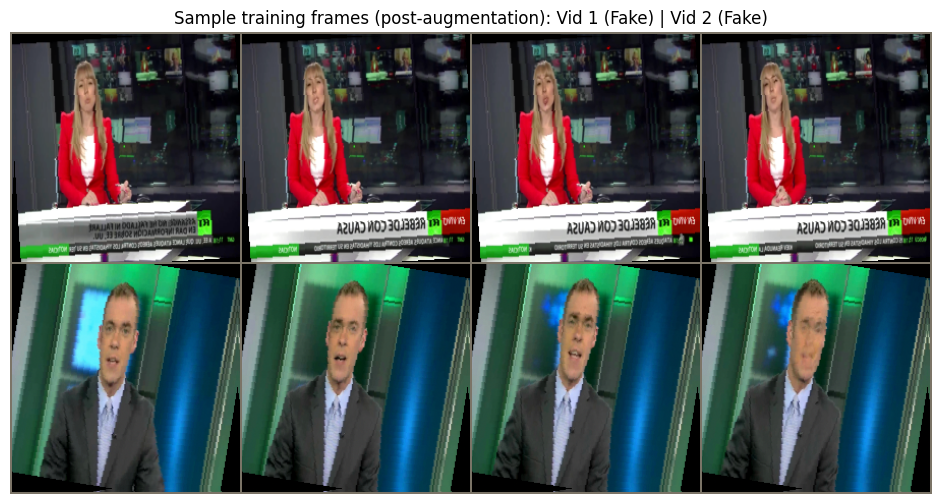

Sample training batch: 8 clips -> real=0, fake=8
Each clip has 16 frames at 224x224 resolution.


In [6]:
# ============================================================
# CELL 5: Dataset visualization
# ============================================================

images, labels = next(iter(train_loader))

video_1_frames = images[0, :4]  # [4, 3, 224, 224]
video_2_frames = images[1, :4]

images_to_show = torch.cat([video_1_frames, video_2_frames], dim=0)
out = make_grid(images_to_show, nrow=4)

mean = torch.tensor(IMAGENET_MEAN, device=out.device).view(3, 1, 1)
std = torch.tensor(IMAGENET_STD, device=out.device).view(3, 1, 1)
out_unnorm = torch.clamp(out * std + mean, 0.0, 1.0)

label_mapping = {0: "Real", 1: "Fake"}
label_1 = label_mapping[int(labels[0].item())]
label_2 = label_mapping[int(labels[1].item())]
titles = f"Vid 1 ({label_1}) | Vid 2 ({label_2})"

img_np = out_unnorm.permute(1, 2, 0).cpu().numpy()

plt.figure(figsize=(12, 6))
plt.imshow(img_np)
plt.title(f"Sample training frames (post-augmentation): {titles}")
plt.axis("off")
plt.show()

# ---- Class balance across the batch, as a sanity check ----
batch_labels = labels.numpy().astype(int)
n_real_batch = int((batch_labels == 0).sum())
n_fake_batch = int((batch_labels == 1).sum())
print(f"Sample training batch: {len(batch_labels)} clips -> real={n_real_batch}, fake={n_fake_batch}")
print(f"Each clip has {images.shape[1]} frames at {images.shape[-2]}x{images.shape[-1]} resolution.")


In [7]:
# ============================================================
# CELL 6: Model architecture
# ============================================================
# EfficientNet-B1 (kept as the spatial backbone, per the brief) -> projection
# layer -> (Bi)LSTM -> learnable temporal attention pooling -> classifier.
# Backbone freeze/unfreeze + discriminative-LR param groups support the
# staged transfer-learning schedule used in Cells 9-10.

class TemporalAttentionPooling(nn.Module):
    """Learnable additive attention over the temporal (frame) dimension.
    Produces both the pooled feature vector and the per-frame attention
    weights (inspectable / visualized in Cell 24)."""
    def __init__(self, input_dim):
        super().__init__()
        self.attn = nn.Sequential(
            nn.Linear(input_dim, input_dim // 2),
            nn.Tanh(),
            nn.Linear(input_dim // 2, 1),
        )

    def forward(self, x):
        # x: [B, T, D]
        scores = self.attn(x)                     # [B, T, 1]
        weights = torch.softmax(scores, dim=1)     # [B, T, 1]
        pooled = torch.sum(weights * x, dim=1)     # [B, D]
        return pooled, weights.squeeze(-1)         # weights: [B, T]


class FFPPDeepfakeDetectorV2(nn.Module):
    def __init__(self,
                 lstm_hidden_size=None, num_layers=None, bidirectional=None,
                 dropout=None, use_attention=None):
        super().__init__()
        lstm_hidden_size = lstm_hidden_size or CONFIG["lstm_hidden_size"]
        num_layers = num_layers or CONFIG["lstm_num_layers"]
        bidirectional = CONFIG["lstm_bidirectional"] if bidirectional is None else bidirectional
        dropout = CONFIG["dropout"] if dropout is None else dropout
        use_attention = CONFIG["use_temporal_attention"] if use_attention is None else use_attention

        # ---- Spatial feature extractor (EfficientNet-B1, unchanged backbone) ----
        weights = EfficientNet_B1_Weights.DEFAULT
        base_model = efficientnet_b1(weights=weights)
        self.feature_extractor = nn.Sequential(*list(base_model.children())[:-1])  # [stages, avgpool]
        self.feature_dim = 1280
        self.dropout_cnn = nn.Dropout(p=dropout)
        self.flatten = nn.Flatten()

        # ---- Projection layer (new) ----
        self.projection = nn.Sequential(
            nn.Linear(self.feature_dim, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
        )

        # ---- Temporal model ----
        self.bidirectional = bidirectional
        self.use_attention = use_attention
        self.lstm = nn.LSTM(
            input_size=512,
            hidden_size=lstm_hidden_size,
            num_layers=num_layers,
            batch_first=True,
            bidirectional=bidirectional,
            dropout=(dropout if num_layers > 1 else 0.0),
        )
        lstm_out_dim = lstm_hidden_size * (2 if bidirectional else 1)

        self.temporal_pool = TemporalAttentionPooling(lstm_out_dim) if use_attention else None

        # ---- Classification head ----
        self.classifier = nn.Sequential(
            nn.Linear(lstm_out_dim, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(p=dropout),
            nn.Linear(256, 1),
        )

        self.last_attention_weights = None  # [B, T] populated each forward if use_attention

    def forward(self, x):
        batch_size, seq_len, c, h, w = x.shape
        x = x.view(batch_size * seq_len, c, h, w)

        features = self.feature_extractor(x)
        features = self.flatten(features)
        features = self.dropout_cnn(features)
        features = self.projection(features)

        features = features.view(batch_size, seq_len, -1)
        lstm_out, _ = self.lstm(features)

        if self.use_attention:
            pooled, attn_weights = self.temporal_pool(lstm_out)
            self.last_attention_weights = attn_weights.detach()
        else:
            pooled = torch.mean(lstm_out, dim=1)
            self.last_attention_weights = None

        out = self.classifier(pooled)
        return out.squeeze(1)

    # ---- Staged transfer-learning helpers ----
    def freeze_backbone(self):
        for p in self.feature_extractor.parameters():
            p.requires_grad = False

    def unfreeze_last_n_blocks(self, n):
        """Unfreezes the last `n` top-level stage blocks of the EfficientNet-B1
        feature extractor (self.feature_extractor[0] holds the MBConv stage
        blocks; [-1] is the final 1x1 conv block, matching the Grad-CAM
        target layer used in Cell 23)."""
        backbone_blocks = list(self.feature_extractor[0].children())
        for block in backbone_blocks[-n:]:
            for p in block.parameters():
                p.requires_grad = True

    def backbone_param_groups(self, backbone_lr, head_lr):
        """Discriminative-LR optimizer param groups: currently-trainable
        backbone params at `backbone_lr`, everything else at `head_lr`."""
        backbone_params = [p for p in self.feature_extractor.parameters() if p.requires_grad]
        head_params = (
            list(self.projection.parameters())
            + list(self.lstm.parameters())
            + (list(self.temporal_pool.parameters()) if self.use_attention else [])
            + list(self.classifier.parameters())
        )
        groups = [{"params": head_params, "lr": head_lr}]
        if backbone_params:
            groups.append({"params": backbone_params, "lr": backbone_lr})
        return groups


def build_model():
    m = FFPPDeepfakeDetectorV2().to(CONFIG["device"])
    m.freeze_backbone()  # Phase 1 always starts with the backbone frozen
    return m


model = build_model()
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Model initialized: EfficientNet-B1 -> projection -> "
      f"{'Bi' if CONFIG['lstm_bidirectional'] else ''}LSTM(hidden={CONFIG['lstm_hidden_size']}, "
      f"layers={CONFIG['lstm_num_layers']}) -> "
      f"{'temporal attention' if CONFIG['use_temporal_attention'] else 'mean'} pooling -> classifier")
print(f"Total params: {total_params:,} | Trainable (Phase 1, backbone frozen): {trainable_params:,}")


Downloading: "https://download.pytorch.org/models/efficientnet_b1-c27df63c.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b1-c27df63c.pth


100%|██████████| 30.1M/30.1M [00:00<00:00, 222MB/s]


Model initialized: EfficientNet-B1 -> projection -> BiLSTM(hidden=512, layers=2) -> temporal attention pooling -> classifier
Total params: 18,459,170 | Trainable (Phase 1, backbone frozen): 11,945,986


In [8]:
# ============================================================
# CELL 7: FGSM/PGD attack functions
# ============================================================
# Unchanged in approach from the working notebook: attacks operate on the
# complete [B, T, C, H, W] video tensor after normalization, convert
# pixel-space epsilon/alpha into normalized-space bounds via the ImageNet
# std, run under autocast, and freeze BatchNorm/Dropout while forcing any
# LSTM/GRU/RNN submodule to stay in train() mode so cuDNN permits the
# backward pass needed to compute the input gradient. Fully architecture-
# agnostic, so this works unchanged against the new attention-pooling model.
#
# The dataset already returns ImageNet-normalized video tensors of shape
# [B, T, 3, 224, 224]. All attacks below operate directly on that
# normalized tensor and perturb every frame of every video consistently.
#
# Because the tensors are normalized, an epsilon specified in pixel space
# (e.g. 4/255) does NOT correspond to the same epsilon in normalized space.
# We convert per-channel using the ImageNet std:
#
#     epsilon_normalized[c] = epsilon_pixel / std[c]
#     alpha_normalized[c]   = alpha_pixel   / std[c]
#
# MEMORY NOTE (fixes CUDA OOM seen at ~14.5/14.56 GiB on the first batch):
# With seq_len=16, a single forward pass already pushes batch_size*seq_len
# (e.g. 8*16=128) images through EfficientNet-B1 at once. The attack's
# forward pass previously ran in full FP32 (no autocast), which uses
# roughly 2x the activation memory of the FP16 forward pass used
# everywhere else in the notebook. That FP32 attack graph, combined with
# holding a second full graph for training right after it, is what
# exhausted the GPU. The attacks below now run under the SAME autocast
# policy as the rest of the pipeline. Autograd still produces a correct
# (FP32) gradient for the FP32 leaf input `x` even though the forward
# math runs in FP16 -- this is the same mechanism PyTorch AMP already
# relies on for parameter gradients. The only trade-off is that a
# vanishingly small number of FP16-underflowed gradient entries may end
# up with a zero sign (a slightly weaker, not incorrect, perturbation at
# those pixels) -- acceptable for FGSM/PGD, which only use the sign.

import torch
import torch.nn as nn

# Renamed (was IMAGENET_MEAN/IMAGENET_STD) to avoid colliding with Cell 1's
# identically-named globals, which are plain 3-element lists used for
# per-frame torchvision normalization in the Dataset class -- reusing the
# same names here for a differently-shaped (5D, video-tensor-broadcastable)
# tensor previously overwrote Cell 1's copies as soon as this cell ran,
# causing a shape-mismatch crash the first time the DataLoader actually
# called Dataset.__getitem__ (lazily, only once training started).
_ATTACK_IMAGENET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 1, 3, 1, 1)
_ATTACK_IMAGENET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 1, 3, 1, 1)


def _prepare_model_for_attack(model):
    """
    Puts BatchNorm/Dropout into eval mode (frozen running stats,
    deterministic) for attack-generation, WHILE forcing any RNN-based
    submodule (LSTM/GRU/RNN) to stay in train() mode.

    This is required because cuDNN's fused RNN kernels only support a
    backward pass when the RNN module's `.training` flag is True; calling
    the whole model's `.eval()` (as attack generation would otherwise want,
    to freeze BatchNorm/Dropout) also flips the LSTM into its
    inference-only cuDNN descriptor, which then raises:
    "RuntimeError: cudnn RNN backward can only be called in training mode"
    the moment we call `torch.autograd.grad(loss, x, ...)`.

    Forcing just the RNN submodules back to train() after the global
    eval() sidesteps that, without reintroducing BatchNorm-statistics
    corruption or dropout noise into the attack.

    Returns a dict of {module: previous_training_bool} so the exact
    original mode of every submodule can be restored afterward.
    """
    prev_modes = {m: m.training for m in model.modules()}
    model.eval()
    for m in model.modules():
        if isinstance(m, (nn.LSTM, nn.GRU, nn.RNN)):
            m.train()
    return prev_modes


def _restore_model_modes(model, prev_modes):
    """Restores every submodule's `.training` flag to what it was before
    `_prepare_model_for_attack` ran."""
    for m in model.modules():
        if m in prev_modes:
            m.train(prev_modes[m])


def _get_norm_bounds(device):
    """Returns per-channel min/max of the normalized input space (i.e. the
    normalized values that correspond to raw pixel values 0 and 1)."""
    mean = _ATTACK_IMAGENET_MEAN.to(device)
    std = _ATTACK_IMAGENET_STD.to(device)
    valid_min = (0.0 - mean) / std
    valid_max = (1.0 - mean) / std
    return valid_min, valid_max


def _epsilon_to_normalized(epsilon_pixel, device):
    """Converts a scalar pixel-space epsilon into a per-channel normalized-space
    tensor of shape [1, 1, 3, 1, 1] broadcastable against [B, T, C, H, W]."""
    std = _ATTACK_IMAGENET_STD.to(device)
    return epsilon_pixel / std


def fgsm_attack(model, videos, labels, epsilon, criterion=None, use_amp=None):
    """
    Fast Gradient Sign Method, applied over the COMPLETE video tensor
    [B, T, C, H, W]. Every frame of a given video is perturbed with the
    same-sign gradient step (i.e. the whole clip is attacked jointly,
    since the gradient already flows through all T frames via the LSTM).

    Args:
        model: FFPPDeepfakeDetector (or any model with matching forward signature)
        videos: clean input tensor [B, T, C, H, W], ImageNet-normalized, NOT requiring grad
        labels: ground-truth labels [B]
        epsilon: perturbation budget in PIXEL space (e.g. 4/255)
        criterion: loss function (defaults to BCEWithLogitsLoss)
        use_amp: whether to run the internal forward pass under autocast
                 (defaults to the global USE_AMP flag set in Cell 5 if available,
                 otherwise True when on CUDA)

    Returns:
        adv_videos: adversarially perturbed video tensor, detached, same shape as `videos`
    """
    if criterion is None:
        criterion = nn.BCEWithLogitsLoss()

    device = videos.device
    if use_amp is None:
        use_amp = globals().get("USE_AMP", device.type == "cuda")

    # Freeze BatchNorm/Dropout for attack generation, but keep any LSTM/GRU/RNN
    # submodule in train() mode so cuDNN's RNN backward kernel is available
    # (see _prepare_model_for_attack docstring above).
    prev_modes = _prepare_model_for_attack(model)

    # Work on a fresh leaf tensor that requires grad; never mutate `videos` in-place.
    x = videos.clone().detach().to(device)
    x.requires_grad_(True)

    if use_amp:
        with torch.amp.autocast("cuda"):
            logits = model(x)
            loss = criterion(logits, labels)
    else:
        logits = model(x)
        loss = criterion(logits, labels)

    # Gradient w.r.t. the INPUT only. Model parameter grads are not needed here.
    grad = torch.autograd.grad(loss, x, retain_graph=False, create_graph=False)[0]

    epsilon_norm = _epsilon_to_normalized(epsilon, device)  # [1,1,3,1,1]
    valid_min, valid_max = _get_norm_bounds(device)

    with torch.no_grad():
        x_adv = x + epsilon_norm * grad.sign()
        # Project the perturbation back into the epsilon ball around the clean input
        perturbation = torch.clamp(x_adv - videos, min=-epsilon_norm, max=epsilon_norm)
        x_adv = videos + perturbation
        # Keep the adversarial example within the valid (un-normalized 0..1 pixel) range
        x_adv = torch.max(torch.min(x_adv, valid_max), valid_min)

    x_adv = x_adv.detach()

    # Clear any residual grads accumulated on model parameters during the backward call,
    # and drop references to the (now unneeded) forward/backward graph promptly.
    model.zero_grad(set_to_none=True)
    del x, logits, loss, grad

    _restore_model_modes(model, prev_modes)

    return x_adv


def pgd_attack(model, videos, labels, epsilon, alpha, steps, criterion=None,
                random_start=True, use_amp=None):
    """
    Projected Gradient Descent attack over the COMPLETE video tensor
    [B, T, C, H, W]. Used ONLY for stronger robustness evaluation
    (never for training, to keep Kaggle runtime practical).

    Args:
        model: FFPPDeepfakeDetector
        videos: clean input tensor [B, T, C, H, W], ImageNet-normalized
        labels: ground-truth labels [B]
        epsilon: perturbation budget in PIXEL space
        alpha: per-step size in PIXEL space
        steps: number of PGD iterations
        criterion: loss function (defaults to BCEWithLogitsLoss)
        random_start: if True, initializes with a small random perturbation inside the epsilon ball
        use_amp: whether to run each step's forward pass under autocast (see fgsm_attack)

    Returns:
        adv_videos: adversarially perturbed video tensor, detached, same shape as `videos`
    """
    if criterion is None:
        criterion = nn.BCEWithLogitsLoss()

    device = videos.device
    if use_amp is None:
        use_amp = globals().get("USE_AMP", device.type == "cuda")

    # Same reasoning as fgsm_attack: freeze BatchNorm/Dropout but force any
    # LSTM/GRU/RNN submodule to stay in train() mode so cuDNN's RNN backward
    # kernel is available for each of the PGD steps below.
    prev_modes = _prepare_model_for_attack(model)

    epsilon_norm = _epsilon_to_normalized(epsilon, device)   # [1,1,3,1,1]
    alpha_norm = _epsilon_to_normalized(alpha, device)       # [1,1,3,1,1]
    valid_min, valid_max = _get_norm_bounds(device)

    videos_clean = videos.clone().detach()

    if random_start:
        rand_noise = (torch.rand_like(videos_clean) * 2 - 1) * epsilon_norm
        x_adv = videos_clean + rand_noise
        x_adv = torch.max(torch.min(x_adv, valid_max), valid_min)
    else:
        x_adv = videos_clean.clone()

    for _ in range(steps):
        x_adv = x_adv.detach()
        x_adv.requires_grad_(True)

        if use_amp:
            with torch.amp.autocast("cuda"):
                logits = model(x_adv)
                loss = criterion(logits, labels)
        else:
            logits = model(x_adv)
            loss = criterion(logits, labels)

        grad = torch.autograd.grad(loss, x_adv, retain_graph=False, create_graph=False)[0]

        with torch.no_grad():
            x_adv = x_adv + alpha_norm * grad.sign()
            # Project back into the epsilon ball around the ORIGINAL clean input
            perturbation = torch.clamp(x_adv - videos_clean, min=-epsilon_norm, max=epsilon_norm)
            x_adv = videos_clean + perturbation
            x_adv = torch.max(torch.min(x_adv, valid_max), valid_min)

        del logits, loss, grad

    model.zero_grad(set_to_none=True)
    _restore_model_modes(model, prev_modes)

    return x_adv.detach()


print("Adversarial attack utilities ready: fgsm_attack(), pgd_attack()")


Adversarial attack utilities ready: fgsm_attack(), pgd_attack()


In [9]:
# ============================================================
# CELL 8: Loss, optimizer, scheduler, metrics
# ============================================================
# Class weighting is computed from TRAIN labels ONLY. Shared train/validate
# epoch functions are defined here and reused by both the clean baseline
# (Cell 9) and ART (Cell 10) training loops to avoid duplicating the
# memory-safe training-step pattern (autocast attacks, split backward
# passes, grad clipping, periodic cache clearing) in two places.

EMPTY_CACHE_EVERY_N_BATCHES = 25

# ---- Class weighting from TRAIN labels only ----
train_labels_arr = np.array([r[1] for r in train_records])
n_neg = int((train_labels_arr == 0).sum())
n_pos = int((train_labels_arr == 1).sum())
print(f"Train label distribution -> real(neg)={n_neg}, fake(pos)={n_pos}")

pos_weight_tensor = None
if CONFIG["use_class_weight"] and n_pos > 0:
    pos_weight_value = n_neg / n_pos
    pos_weight_tensor = torch.tensor([pos_weight_value], device=CONFIG["device"])
    print(f"Using pos_weight={pos_weight_value:.4f} in BCEWithLogitsLoss "
          f"(computed from TRAIN labels only)")
else:
    print("Class weighting disabled or no positive samples -- using unweighted BCEWithLogitsLoss")


class FocalLossWithLogits(nn.Module):
    """Optional -- off by default (CONFIG['use_focal_loss']). Standard binary
    focal loss built on top of BCEWithLogitsLoss so it still respects pos_weight."""
    def __init__(self, gamma=2.0, pos_weight=None):
        super().__init__()
        self.gamma = gamma
        self.pos_weight = pos_weight

    def forward(self, logits, targets):
        bce = Fn.binary_cross_entropy_with_logits(
            logits, targets, pos_weight=self.pos_weight, reduction="none"
        )
        probs = torch.sigmoid(logits)
        pt = torch.where(targets == 1, probs, 1 - probs)
        focal_term = (1 - pt).clamp(min=1e-6) ** self.gamma
        return (focal_term * bce).mean()


if CONFIG["use_focal_loss"]:
    criterion = FocalLossWithLogits(gamma=CONFIG["focal_gamma"], pos_weight=pos_weight_tensor)
    print(f"Using FocalLossWithLogits (gamma={CONFIG['focal_gamma']})")
else:
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)


def build_optimizer(model):
    """Discriminative-LR AdamW: works for both Phase 1 (backbone has zero
    trainable params, so only the head param group is non-empty) and
    Phase 2 (both groups populated) without any special-casing."""
    param_groups = model.backbone_param_groups(
        backbone_lr=CONFIG["backbone_lr"], head_lr=CONFIG["head_lr"]
    )
    return torch.optim.AdamW(param_groups, lr=CONFIG["head_lr"], weight_decay=CONFIG["weight_decay"])


def build_scheduler(optimizer):
    # Paired with early stopping on validation F1 -- reduces LR when
    # validation F1 plateaus, which suits the two-phase (differently-sized)
    # discriminative-LR schedule better than a step count-based scheduler.
    return torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode="max",
        factor=CONFIG["scheduler_factor"],
        patience=CONFIG["scheduler_patience"],
    )


def train_epoch(model, loader, optimizer, criterion, scaler, use_amp,
                 adversarial=False, epsilon=None,
                 adv_loss_weight=None, clean_loss_weight=None,
                 grad_clip_norm=None):
    model.train()
    running_loss = running_clean_loss = running_adv_loss = 0.0
    n_samples = 0
    all_preds, all_labels = [], []

    for batch_idx, (videos, labels) in enumerate(tqdm(loader, desc="Training", leave=False)):
        videos = videos.to(CONFIG["device"], non_blocking=True)
        labels = labels.to(CONFIG["device"], non_blocking=True)
        bs = videos.size(0)

        if adversarial:
            adv_videos = fgsm_attack(model, videos, labels, epsilon=epsilon,
                                      criterion=criterion, use_amp=use_amp)

        optimizer.zero_grad(set_to_none=True)

        if use_amp:
            with torch.amp.autocast("cuda"):
                clean_logits = model(videos)
                clean_loss = criterion(clean_logits, labels)
            clean_weight = clean_loss_weight if adversarial else 1.0
            scaler.scale(clean_weight * clean_loss).backward()

            if adversarial:
                with torch.amp.autocast("cuda"):
                    adv_logits = model(adv_videos)
                    adv_loss = criterion(adv_logits, labels)
                scaler.scale(adv_loss_weight * adv_loss).backward()

            if grad_clip_norm:
                scaler.unscale_(optimizer)
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip_norm)
            scaler.step(optimizer)
            scaler.update()
        else:
            clean_logits = model(videos)
            clean_loss = criterion(clean_logits, labels)
            clean_weight = clean_loss_weight if adversarial else 1.0
            (clean_weight * clean_loss).backward()

            if adversarial:
                adv_logits = model(adv_videos)
                adv_loss = criterion(adv_logits, labels)
                (adv_loss_weight * adv_loss).backward()

            if grad_clip_norm:
                torch.nn.utils.clip_grad_norm_(model.parameters(), grad_clip_norm)
            optimizer.step()

        batch_loss = clean_weight * clean_loss.item()
        if adversarial:
            batch_loss += adv_loss_weight * adv_loss.item()
            running_adv_loss += adv_loss.item() * bs

        running_loss += batch_loss * bs
        running_clean_loss += clean_loss.item() * bs
        n_samples += bs

        all_preds.extend(torch.sigmoid(clean_logits).detach().cpu().numpy())
        all_labels.extend(labels.detach().cpu().numpy())

        if adversarial:
            del adv_videos, adv_logits, adv_loss
        del clean_logits, clean_loss

        if (batch_idx + 1) % EMPTY_CACHE_EVERY_N_BATCHES == 0:
            free_cuda_memory()

    preds_bin = (np.array(all_preds) >= 0.5).astype(int)
    metrics = {
        "loss": running_loss / n_samples,
        "clean_loss": running_clean_loss / n_samples,
        "acc": accuracy_score(all_labels, preds_bin),
    }
    if adversarial:
        metrics["adv_loss"] = running_adv_loss / n_samples
    return metrics


def validate_epoch(model, loader, criterion, threshold=0.5, use_amp=USE_AMP):
    model.eval()
    all_preds, all_labels = [], []
    running_loss, n = 0.0, 0
    with torch.no_grad():
        for videos, labels in tqdm(loader, desc="Validating", leave=False):
            videos = videos.to(CONFIG["device"], non_blocking=True)
            labels = labels.to(CONFIG["device"], non_blocking=True)
            if use_amp:
                with torch.amp.autocast("cuda"):
                    logits = model(videos)
                    loss = criterion(logits, labels)
            else:
                logits = model(videos)
                loss = criterion(logits, labels)
            bs = videos.size(0)
            running_loss += loss.item() * bs
            n += bs
            all_preds.extend(torch.sigmoid(logits).cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
    m = compute_metrics(all_labels, all_preds, threshold=threshold)
    m["loss"] = running_loss / n
    return m


def validate_epoch_adversarial(model, loader, criterion, epsilon, threshold=0.5, use_amp=USE_AMP):
    model.eval()
    all_preds, all_labels = [], []
    running_loss, n = 0.0, 0
    for videos, labels in tqdm(loader, desc="Validating (FGSM)", leave=False):
        videos = videos.to(CONFIG["device"], non_blocking=True)
        labels = labels.to(CONFIG["device"], non_blocking=True)
        adv_videos = fgsm_attack(model, videos, labels, epsilon=epsilon,
                                  criterion=criterion, use_amp=use_amp)
        with torch.no_grad():
            if use_amp:
                with torch.amp.autocast("cuda"):
                    logits = model(adv_videos)
                    loss = criterion(logits, labels)
            else:
                logits = model(adv_videos)
                loss = criterion(logits, labels)
        bs = videos.size(0)
        running_loss += loss.item() * bs
        n += bs
        all_preds.extend(torch.sigmoid(logits).cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        del adv_videos
    m = compute_metrics(all_labels, all_preds, threshold=threshold)
    m["loss"] = running_loss / n
    return m


print("Loss/optimizer/scheduler builders and shared train/validate epoch functions ready.")


Train label distribution -> real(neg)=700, fake(pos)=3500
Using pos_weight=0.2000 in BCEWithLogitsLoss (computed from TRAIN labels only)
Loss/optimizer/scheduler builders and shared train/validate epoch functions ready.


In [10]:
# ============================================================
# CELL 9: Clean training baseline
# ============================================================
# Staged transfer learning: Phase 1 trains the (projection + LSTM +
# attention + classifier) head with the backbone frozen; Phase 2 unfreezes
# the last few EfficientNet-B1 blocks and fine-tunes everything with
# discriminative learning rates. Early stopping + checkpointing are both
# driven ONLY by validation F1 -- the test set is never touched here.
#
# `run_staged_training` is written once here and reused unchanged by the
# ART run in Cell 10 (adversarial=True), so both models are trained with
# an identical schedule and only differ by the adversarial objective.

def run_staged_training(model, save_path, adversarial=False, epsilon=None,
                         adv_loss_weight=None, clean_loss_weight=None,
                         history_tag="clean"):
    history = []
    best_val_f1 = -1.0
    epochs_without_improvement = 0
    global_epoch = 0

    phases = [
        ("Phase 1 (backbone frozen)", CONFIG["phase1_epochs"], False),
        ("Phase 2 (fine-tuning)", CONFIG["phase2_epochs"], True),
    ]

    for phase_name, n_epochs, do_unfreeze in phases:
        if do_unfreeze:
            model.unfreeze_last_n_blocks(CONFIG["unfreeze_last_n_blocks"])

        optimizer = build_optimizer(model)
        scheduler = build_scheduler(optimizer)
        scaler = torch.amp.GradScaler("cuda") if USE_AMP else None

        trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"\n{'=' * 60}\n{phase_name} -- {n_epochs} epochs -- "
              f"trainable params: {trainable:,}\n{'=' * 60}")

        for epoch_in_phase in range(n_epochs):
            global_epoch += 1

            train_metrics = train_epoch(
                model, train_loader, optimizer, criterion, scaler, USE_AMP,
                adversarial=adversarial, epsilon=epsilon,
                adv_loss_weight=adv_loss_weight, clean_loss_weight=clean_loss_weight,
                grad_clip_norm=CONFIG["grad_clip_norm"],
            )
            val_metrics = validate_epoch(model, val_loader, criterion, threshold=0.5, use_amp=USE_AMP)

            current_lr = optimizer.param_groups[0]["lr"]
            # Checkpoint selection uses CLEAN validation F1 for both the clean
            # baseline and the ART model, for a fair apples-to-apples
            # comparison; FGSM validation metrics are additionally tracked/
            # printed below for visibility into robustness during training.
            scheduler.step(val_metrics["f1"])

            print(f"\nEpoch {global_epoch} ({phase_name}, {epoch_in_phase + 1}/{n_epochs})")
            print(f"  Train Loss: {train_metrics['loss']:.4f} | Train Acc: {train_metrics['acc']:.4f}")
            print(f"  Val   Loss: {val_metrics['loss']:.4f} | Val Acc: {val_metrics['accuracy']:.4f} | "
                  f"Val Precision: {val_metrics['precision']:.4f} | Val Recall: {val_metrics['recall']:.4f} | "
                  f"Val F1: {val_metrics['f1']:.4f} | Val ROC-AUC: {val_metrics['roc_auc']:.4f}")
            print(f"  Learning rate: {current_lr:.2e}")

            epoch_record = {
                "epoch": global_epoch, "phase": phase_name, "lr": current_lr,
                **{f"train_{k}": v for k, v in train_metrics.items()},
                **{f"val_{k}": v for k, v in val_metrics.items()},
            }

            if adversarial:
                val_adv_metrics = validate_epoch_adversarial(
                    model, val_loader, criterion, epsilon=epsilon, threshold=0.5, use_amp=USE_AMP
                )
                print(f"  Val (FGSM) Acc: {val_adv_metrics['accuracy']:.4f} | "
                      f"F1: {val_adv_metrics['f1']:.4f} | ROC-AUC: {val_adv_metrics['roc_auc']:.4f}")
                epoch_record.update({f"val_adv_{k}": v for k, v in val_adv_metrics.items()})

            history.append(epoch_record)

            if val_metrics["f1"] > best_val_f1:
                best_val_f1 = val_metrics["f1"]
                epochs_without_improvement = 0
                torch.save(model.state_dict(), save_path)
                print(f"  --> Best {history_tag} model saved (val F1={best_val_f1:.4f}) -> {save_path}")
            else:
                epochs_without_improvement += 1

            if epochs_without_improvement >= CONFIG["early_stopping_patience"]:
                print(f"  Early stopping triggered ({history_tag}) after {global_epoch} total epochs.")
                del optimizer, scheduler, scaler
                free_cuda_memory()
                return history, best_val_f1

        del optimizer, scheduler, scaler
        free_cuda_memory()

    return history, best_val_f1


set_seed(CONFIG["seed"])
print("=" * 60)
print("CLEAN BASELINE TRAINING (no adversarial training)")
print("=" * 60)

clean_model = build_model()
clean_history, clean_best_val_f1 = run_staged_training(
    clean_model, CONFIG["save_clean_checkpoint"], adversarial=False, history_tag="clean"
)
print(f"\nClean baseline training complete. Best validation F1: {clean_best_val_f1:.4f}")


CLEAN BASELINE TRAINING (no adversarial training)

Phase 1 (backbone frozen) -- 3 epochs -- trainable params: 11,945,986


Training:   0%|          | 0/525 [00:00<?, ?it/s]

Validating:   0%|          | 0/38 [00:00<?, ?it/s]


Epoch 1 (Phase 1 (backbone frozen), 1/3)
  Train Loss: 0.2314 | Train Acc: 0.4302
  Val   Loss: 0.4168 | Val Acc: 0.5033 | Val Precision: 0.5175 | Val Recall: 0.5033 | Val F1: 0.3772 | Val ROC-AUC: 0.5240
  Learning rate: 1.00e-04
  --> Best clean model saved (val F1=0.3772) -> /kaggle/working/best_clean_model.pth


Training:   0%|          | 0/525 [00:00<?, ?it/s]

...

Validating:   0%|          | 0/38 [00:00<?, ?it/s]


Epoch 6 (Phase 2 (fine-tuning), 3/4)
  Train Loss: 0.2108 | Train Acc: 0.6074
  Val   Loss: 0.3152 | Val Acc: 0.6033 | Val Precision: 0.6378 | Val Recall: 0.6033 | Val F1: 0.5769 | Val ROC-AUC: 0.7194
  Learning rate: 1.00e-04


Training:   0%|          | 0/525 [00:00<?, ?it/s]

Validating:   0%|          | 0/38 [00:00<?, ?it/s]


Epoch 7 (Phase 2 (fine-tuning), 4/4)
  Train Loss: 0.2030 | Train Acc: 0.6343
  Val   Loss: 0.3537 | Val Acc: 0.6367 | Val Precision: 0.6406 | Val Recall: 0.6367 | Val F1: 0.6341 | Val ROC-AUC: 0.7359
  Learning rate: 1.00e-04
  --> Best clean model saved (val F1=0.6341) -> /kaggle/working/best_clean_model.pth

Clean baseline training complete. Best validation F1: 0.6341


In [11]:
# ============================================================
# CELL 10: ART training
# ============================================================
# Same staged schedule as Cell 9 (via the shared `run_staged_training`),
# with the adversarial combined objective enabled:
#   total_loss = clean_loss_weight * clean_loss + adv_loss_weight * adv_loss
# FGSM perturbations are generated from the TRAINING batch only, never
# update model weights during generation, and the combined loss is
# backpropagated in two memory-safe sequential passes (see Cell 8).

set_seed(CONFIG["seed"])  # identical starting RNG state to the clean run in Cell 9
print("=" * 60)
print("ADVERSARIAL ROBUSTNESS TRAINING (FGSM)")
print(f"epsilon={CONFIG['epsilon']:.4f} (px)  |  adv_loss_weight={CONFIG['adv_loss_weight']}  |  "
      f"clean_loss_weight={CONFIG['clean_loss_weight']}")
print("=" * 60)

art_model = build_model()
art_history, art_best_val_f1 = run_staged_training(
    art_model, CONFIG["save_art_checkpoint"], adversarial=True,
    epsilon=CONFIG["epsilon"],
    adv_loss_weight=CONFIG["adv_loss_weight"],
    clean_loss_weight=CONFIG["clean_loss_weight"],
    history_tag="ART",
)
print(f"\nART training complete. Best validation F1: {art_best_val_f1:.4f}")


ADVERSARIAL ROBUSTNESS TRAINING (FGSM)
epsilon=0.0157 (px)  |  adv_loss_weight=0.5  |  clean_loss_weight=0.5

Phase 1 (backbone frozen) -- 3 epochs -- trainable params: 11,945,986


Training:   0%|          | 0/525 [00:00<?, ?it/s]

Validating:   0%|          | 0/38 [00:00<?, ?it/s]


Epoch 1 (Phase 1 (backbone frozen), 1/3)
  Train Loss: 0.2313 | Train Acc: 0.4612
  Val   Loss: 0.4173 | Val Acc: 0.5300 | Val Precision: 0.5442 | Val Recall: 0.5300 | Val F1: 0.4890 | Val ROC-AUC: 0.5452
  Learning rate: 1.00e-04


Validating (FGSM):   0%|          | 0/38 [00:00<?, ?it/s]

...

Training:   0%|          | 0/525 [00:00<?, ?it/s]

Validating:   0%|          | 0/38 [00:00<?, ?it/s]


Epoch 7 (Phase 2 (fine-tuning), 4/4)
  Train Loss: 0.1763 | Train Acc: 0.2248
  Val   Loss: 2.6493 | Val Acc: 0.5067 | Val Precision: 0.6267 | Val Recall: 0.5067 | Val F1: 0.3536 | Val ROC-AUC: 0.5209
  Learning rate: 1.00e-04


Validating (FGSM):   0%|          | 0/38 [00:00<?, ?it/s]

  Val (FGSM) Acc: 0.9700 | F1: 0.9700 | ROC-AUC: 0.9990

ART training complete. Best validation F1: 0.5142


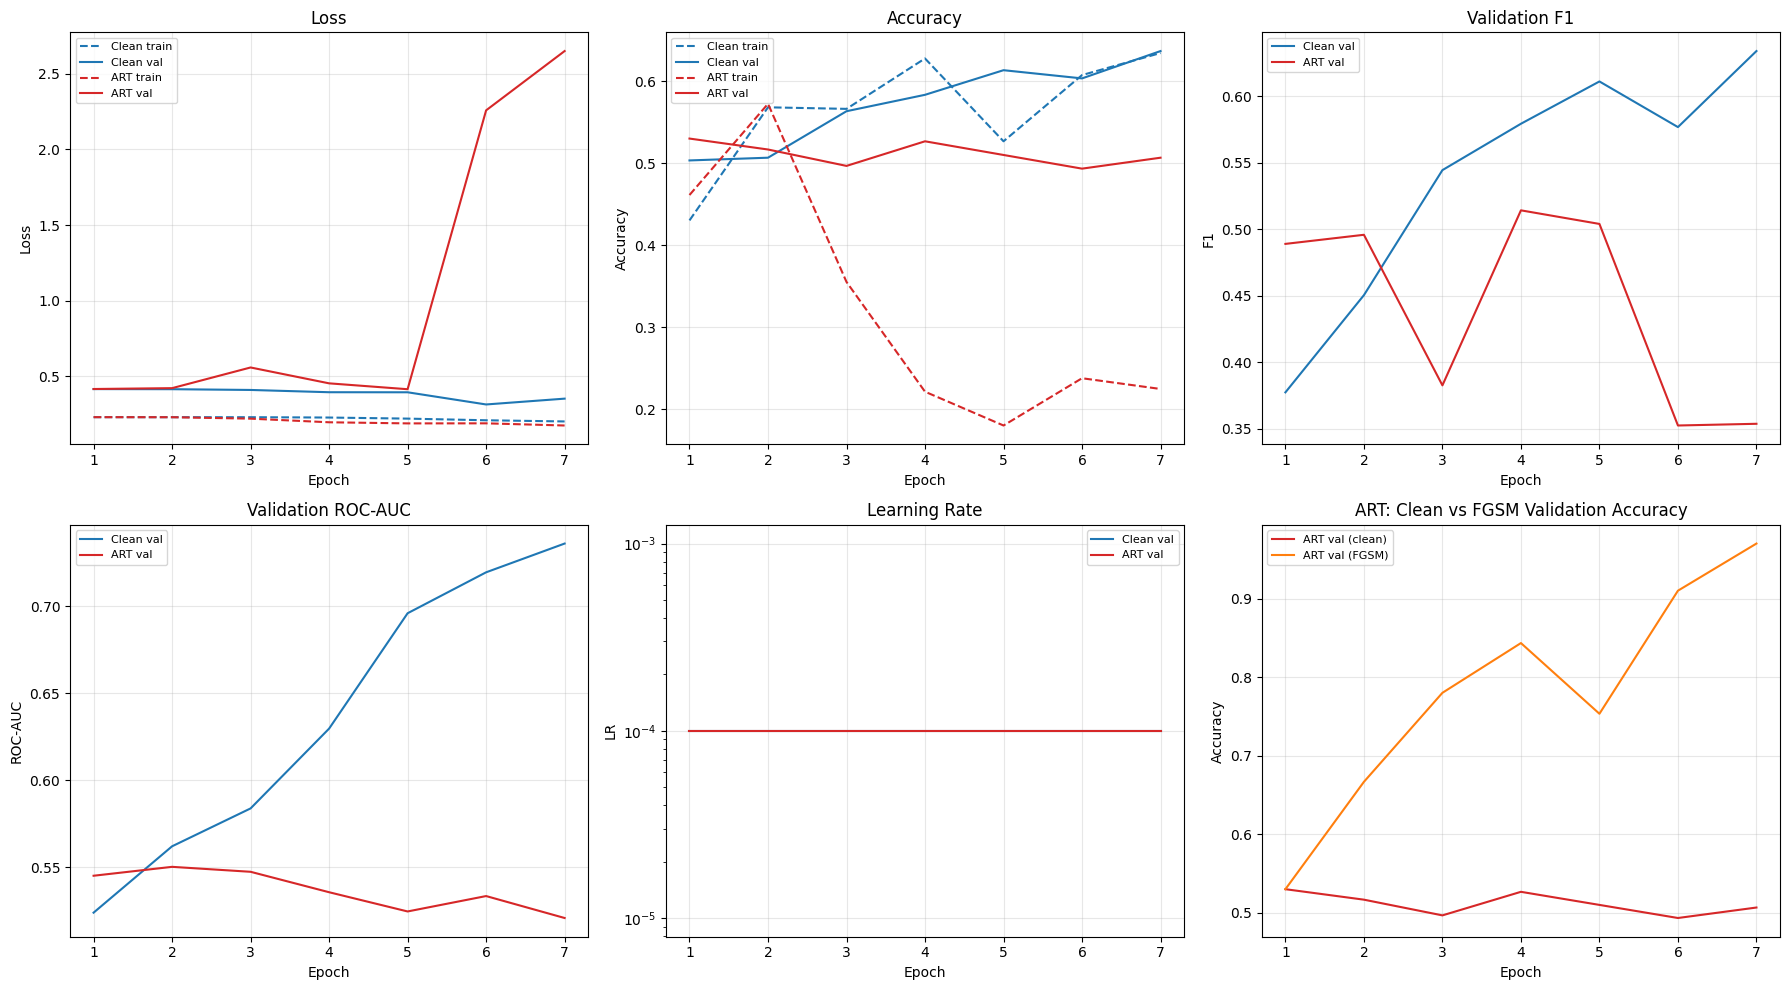

Best clean validation F1: 0.6341
Best ART validation F1  : 0.5142


In [12]:
# ============================================================
# CELL 11: Training curves and validation analysis
# ============================================================

clean_df = pd.DataFrame(clean_history)
art_df = pd.DataFrame(art_history)


def plot_metric(ax, key_train, key_val, title, ylabel):
    if key_train and key_train in clean_df:
        ax.plot(clean_df["epoch"], clean_df[key_train], "--", label="Clean train", color="tab:blue")
    if key_val in clean_df:
        ax.plot(clean_df["epoch"], clean_df[key_val], label="Clean val", color="tab:blue")
    if key_train and key_train in art_df:
        ax.plot(art_df["epoch"], art_df[key_train], "--", label="ART train", color="tab:red")
    if key_val in art_df:
        ax.plot(art_df["epoch"], art_df[key_val], label="ART val", color="tab:red")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)


fig, axes = plt.subplots(2, 3, figsize=(18, 10))

plot_metric(axes[0, 0], "train_loss", "val_loss", "Loss", "Loss")
plot_metric(axes[0, 1], "train_acc", "val_accuracy", "Accuracy", "Accuracy")
plot_metric(axes[0, 2], None, "val_f1", "Validation F1", "F1")
plot_metric(axes[1, 0], None, "val_roc_auc", "Validation ROC-AUC", "ROC-AUC")

plot_metric(axes[1, 1], None, "lr", "Learning Rate", "LR")
axes[1, 1].set_yscale("log")

if "val_adv_accuracy" in art_df.columns:
    axes[1, 2].plot(art_df["epoch"], art_df["val_accuracy"], label="ART val (clean)", color="tab:red")
    axes[1, 2].plot(art_df["epoch"], art_df["val_adv_accuracy"], label="ART val (FGSM)", color="tab:orange")
    axes[1, 2].set_title("ART: Clean vs FGSM Validation Accuracy")
    axes[1, 2].set_xlabel("Epoch")
    axes[1, 2].set_ylabel("Accuracy")
    axes[1, 2].legend(fontsize=8)
    axes[1, 2].grid(alpha=0.3)
else:
    axes[1, 2].axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/training_curves.png", dpi=150)
plt.show()

print(f"Best clean validation F1: {clean_best_val_f1:.4f}")
print(f"Best ART validation F1  : {art_best_val_f1:.4f}")


In [13]:
# ============================================================
# CELL 12: Best model loading
# ============================================================
# Loads each best checkpoint IN PLACE into the existing model object from
# Cells 9/10 (rather than instantiating fresh models) -- avoids ever having
# duplicate EfficientNet-B1+LSTM weights on the GPU at once. Both
# `clean_model` and `art_model` are needed simultaneously for the Cell 18
# comparison, so both stay loaded; their optimizers/schedulers were already
# freed at the end of each training phase in Cell 9/10.

free_cuda_memory()

clean_model.load_state_dict(torch.load(CONFIG["save_clean_checkpoint"], map_location=CONFIG["device"]))
clean_model.eval()

art_model.load_state_dict(torch.load(CONFIG["save_art_checkpoint"], map_location=CONFIG["device"]))
art_model.eval()

print(f"Loaded best clean model from {CONFIG['save_clean_checkpoint']} (val F1={clean_best_val_f1:.4f})")
print(f"Loaded best ART model from {CONFIG['save_art_checkpoint']} (val F1={art_best_val_f1:.4f})")


Loaded best clean model from /kaggle/working/best_clean_model.pth (val F1=0.6341)
Loaded best ART model from /kaggle/working/best_art_model.pth (val F1=0.5142)


In [14]:
# ============================================================
# CELL 13: Clean test evaluation
# ============================================================
# Quick sanity-check evaluation of the ART-trained model on the untouched
# clean test set at the default threshold (0.5). The test set is used here
# for reporting ONLY -- no tuning, thresholding, or model selection decision
# is made from these numbers (that would be data leakage).

def get_raw_predictions(model, loader, use_amp=USE_AMP):
    model.eval()
    all_probs, all_labels = [], []
    with torch.no_grad():
        for videos, labels in tqdm(loader, desc="Evaluating", leave=False):
            videos = videos.to(CONFIG["device"], non_blocking=True)
            if use_amp:
                with torch.amp.autocast("cuda"):
                    logits = model(videos)
            else:
                logits = model(videos)
            all_probs.extend(torch.sigmoid(logits).cpu().numpy())
            all_labels.extend(labels.numpy())
    return np.array(all_labels).astype(int), np.array(all_probs)


art_test_labels, art_test_probs = get_raw_predictions(art_model, test_loader)
art_test_metrics_default = compute_metrics(art_test_labels, art_test_probs, threshold=0.5)

print("=" * 60)
print("CLEAN TEST EVALUATION -- ART model, default threshold = 0.5")
print("=" * 60)
print_metrics("ART test", art_test_metrics_default)


Evaluating:   0%|          | 0/38 [00:00<?, ?it/s]

CLEAN TEST EVALUATION -- ART model, default threshold = 0.5
[ART test] thr=0.500  Acc=0.5100  F1=0.4954  ROC-AUC=0.4978  PR-AUC=0.5134  BalAcc=0.5100


Evaluating:   0%|          | 0/38 [00:00<?, ?it/s]

VALIDATION THRESHOLD SELECTION
Searched thresholds 0.3-0.7 (step=0.01) on the VALIDATION set, selecting by macro F1.
Selected threshold: 0.520  (validation F1=0.5396, validation accuracy=0.5433)
This threshold is now FROZEN for all test-set evaluation in the rest of the notebook.


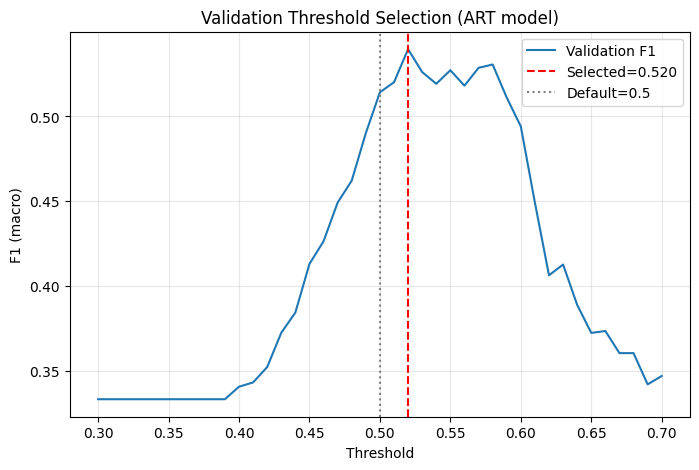

In [15]:
# ============================================================
# CELL 14: Validation threshold selection
# ============================================================
# Selects the classification threshold using ONLY the validation set,
# searching [threshold_search_min, threshold_search_max] and maximizing
# macro F1. The result is then FROZEN and applied to the test set in
# Cell 15 -- test labels are never used for this selection.

val_labels, val_probs = get_raw_predictions(art_model, val_loader)

thresholds = np.arange(
    CONFIG["threshold_search_min"],
    CONFIG["threshold_search_max"] + 1e-9,
    CONFIG["threshold_search_step"],
)

threshold_results = []
for t in thresholds:
    m = compute_metrics(val_labels, val_probs, threshold=float(t))
    threshold_results.append({
        "threshold": float(t), "f1": m["f1"],
        "accuracy": m["accuracy"], "balanced_accuracy": m["balanced_accuracy"],
    })

threshold_df = pd.DataFrame(threshold_results)
best_row = threshold_df.loc[threshold_df["f1"].idxmax()]
selected_threshold = float(best_row["threshold"])

print("=" * 60)
print("VALIDATION THRESHOLD SELECTION")
print("=" * 60)
print(f"Searched thresholds {CONFIG['threshold_search_min']}-{CONFIG['threshold_search_max']} "
      f"(step={CONFIG['threshold_search_step']}) on the VALIDATION set, selecting by macro F1.")
print(f"Selected threshold: {selected_threshold:.3f}  (validation F1={best_row['f1']:.4f}, "
      f"validation accuracy={best_row['accuracy']:.4f})")
print("This threshold is now FROZEN for all test-set evaluation in the rest of the notebook.")

plt.figure(figsize=(8, 5))
plt.plot(threshold_df["threshold"], threshold_df["f1"], label="Validation F1")
plt.axvline(selected_threshold, color="red", linestyle="--", label=f"Selected={selected_threshold:.3f}")
plt.axvline(0.5, color="gray", linestyle=":", label="Default=0.5")
plt.xlabel("Threshold")
plt.ylabel("F1 (macro)")
plt.title("Validation Threshold Selection (ART model)")
plt.legend()
plt.grid(alpha=0.3)
plt.savefig("/kaggle/working/threshold_selection.png", dpi=150)
plt.show()


In [16]:
# ============================================================
# CELL 15: Final test evaluation with selected threshold
# ============================================================
# Reuses the test-set predictions already computed in Cell 13 (no repeated
# inference). Reports both the default threshold (0.5) and the
# validation-selected threshold from Cell 14, side by side.

art_test_metrics_selected = compute_metrics(art_test_labels, art_test_probs, threshold=selected_threshold)

print("=" * 60)
print("FINAL TEST EVALUATION -- ART model")
print("=" * 60)
print_metrics("ART test @0.5 (default)", art_test_metrics_default)
print_metrics(f"ART test @{selected_threshold:.3f} (selected)", art_test_metrics_selected)

preds_selected = (art_test_probs >= selected_threshold).astype(int)
print("\nClassification report @ selected threshold:")
print(classification_report(art_test_labels, preds_selected, target_names=["Real", "Fake"]))

final_test_summary_df = pd.DataFrame([
    {"Threshold": "0.5 (default)", **art_test_metrics_default},
    {"Threshold": f"{selected_threshold:.3f} (selected)", **art_test_metrics_selected},
])
print("\nSummary table:")
print(final_test_summary_df[
    ["Threshold", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "balanced_accuracy"]
].to_string(index=False))


FINAL TEST EVALUATION -- ART model
[ART test @0.5 (default)] thr=0.500  Acc=0.5100  F1=0.4954  ROC-AUC=0.4978  PR-AUC=0.5134  BalAcc=0.5100
[ART test @0.520 (selected)] thr=0.520  Acc=0.4833  F1=0.4824  ROC-AUC=0.4978  PR-AUC=0.5134  BalAcc=0.4833

Classification report @ selected threshold:
              precision    recall  f1-score   support

        Real       0.48      0.44      0.46       150
        Fake       0.48      0.53      0.50       150

    accuracy                           0.48       300
   macro avg       0.48      0.48      0.48       300
weighted avg       0.48      0.48      0.48       300


Summary table:
       Threshold  accuracy  precision   recall       f1  roc_auc   pr_auc  balanced_accuracy
   0.5 (default)  0.510000   0.511307 0.510000 0.495418 0.497844 0.513359           0.510000
0.520 (selected)  0.483333   0.483207 0.483333 0.482361 0.497844 0.513359           0.483333


In [17]:
# ============================================================
# CELL 16: FGSM robustness evaluation
# ============================================================
# All robustness metrics from here on use the validation-selected,
# now-frozen threshold from Cell 14 for consistency.

def evaluate_attack(model, loader, attack_fn, threshold, use_amp=USE_AMP):
    model.eval()
    all_probs, all_labels = [], []
    for videos, labels in tqdm(loader, desc="Evaluating attack", leave=False):
        videos = videos.to(CONFIG["device"], non_blocking=True)
        labels_dev = labels.to(CONFIG["device"], non_blocking=True)
        eval_videos = attack_fn(model, videos, labels_dev) if attack_fn is not None else videos
        with torch.no_grad():
            if use_amp:
                with torch.amp.autocast("cuda"):
                    logits = model(eval_videos)
            else:
                logits = model(eval_videos)
        all_probs.extend(torch.sigmoid(logits).cpu().numpy())
        all_labels.extend(labels.numpy())
    labels_arr = np.array(all_labels).astype(int)
    probs_arr = np.array(all_probs)
    return compute_metrics(labels_arr, probs_arr, threshold=threshold)


fgsm_epsilons = [2 / 255, 4 / 255, 8 / 255]
fgsm_rows = [{"Condition": "Clean", "Epsilon": 0.0, **art_test_metrics_selected}]

for eps in fgsm_epsilons:
    attack_fn = lambda m, v, l, eps=eps: fgsm_attack(m, v, l, epsilon=eps, criterion=criterion)
    m = evaluate_attack(art_model, test_loader, attack_fn, threshold=selected_threshold)
    fgsm_rows.append({"Condition": f"FGSM {round(eps * 255)}/255", "Epsilon": eps, **m})

fgsm_df = pd.DataFrame(fgsm_rows)
clean_acc_ref = fgsm_df.loc[fgsm_df["Condition"] == "Clean", "accuracy"].iloc[0]
clean_f1_ref = fgsm_df.loc[fgsm_df["Condition"] == "Clean", "f1"].iloc[0]
clean_roc_ref = fgsm_df.loc[fgsm_df["Condition"] == "Clean", "roc_auc"].iloc[0]

fgsm_df["Accuracy Drop"] = clean_acc_ref - fgsm_df["accuracy"]
fgsm_df["F1 Drop"] = clean_f1_ref - fgsm_df["f1"]
fgsm_df["ROC-AUC Drop"] = clean_roc_ref - fgsm_df["roc_auc"]
fgsm_df["Retention %"] = np.where(clean_acc_ref > 0, fgsm_df["accuracy"] / clean_acc_ref * 100.0, 0.0)

print("=" * 60)
print(f"FGSM ROBUSTNESS EVALUATION -- ART model (threshold={selected_threshold:.3f})")
print("=" * 60)
print(fgsm_df[[
    "Condition", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc",
    "balanced_accuracy", "Accuracy Drop", "F1 Drop", "ROC-AUC Drop", "Retention %",
]].to_string(index=False))


Evaluating attack:   0%|          | 0/38 [00:00<?, ?it/s]

Evaluating attack:   0%|          | 0/38 [00:00<?, ?it/s]

Evaluating attack:   0%|          | 0/38 [00:00<?, ?it/s]

FGSM ROBUSTNESS EVALUATION -- ART model (threshold=0.520)
 Condition  accuracy  precision   recall       f1  roc_auc   pr_auc  balanced_accuracy  Accuracy Drop   F1 Drop  ROC-AUC Drop  Retention %
     Clean  0.483333   0.483207 0.483333 0.482361 0.497844 0.513359           0.483333       0.000000  0.000000      0.000000   100.000000
FGSM 2/255  0.626667   0.720999 0.626667 0.582069 0.793133 0.775757           0.626667      -0.143333 -0.099707     -0.295289   129.655172
FGSM 4/255  0.826667   0.833848 0.826667 0.825729 0.923556 0.926176           0.826667      -0.343333 -0.343368     -0.425711   171.034483
FGSM 8/255  0.920000   0.920299 0.920000 0.919986 0.974667 0.975675           0.920000      -0.436667 -0.437624     -0.476822   190.344828


In [18]:
# ============================================================
# CELL 17: PGD robustness evaluation
# ============================================================
# PGD is evaluation-only (never used for training, to keep Kaggle runtime
# practical -- see Cell 7/10). PGD-10 is optional and off by default; flip
# RUN_PGD10 to True if you have runtime budget to spare.

RUN_PGD10 = False

pgd_configs = [("PGD-3", 3), ("PGD-5", 5)]
if RUN_PGD10:
    pgd_configs.append(("PGD-10", 10))

pgd_rows = [{"Condition": "Clean", **art_test_metrics_selected}]
fgsm4_row = fgsm_df[np.isclose(fgsm_df["Epsilon"], 4 / 255)].iloc[0]
pgd_rows.append({"Condition": "FGSM 4/255", **{k: fgsm4_row[k] for k in art_test_metrics_selected}})

for name, steps in pgd_configs:
    attack_fn = lambda m, v, l, steps=steps: pgd_attack(
        m, v, l, epsilon=4 / 255, alpha=CONFIG["adv_alpha"], steps=steps, criterion=criterion
    )
    m = evaluate_attack(art_model, test_loader, attack_fn, threshold=selected_threshold)
    pgd_rows.append({"Condition": f"{name} 4/255", **m})

pgd_df = pd.DataFrame(pgd_rows)
pgd_df["Accuracy Drop"] = clean_acc_ref - pgd_df["accuracy"]
pgd_df["F1 Drop"] = clean_f1_ref - pgd_df["f1"]
pgd_df["ROC-AUC Drop"] = clean_roc_ref - pgd_df["roc_auc"]
pgd_df["Retention %"] = np.where(clean_acc_ref > 0, pgd_df["accuracy"] / clean_acc_ref * 100.0, 0.0)

print("=" * 60)
print(f"PGD ROBUSTNESS EVALUATION -- ART model (threshold={selected_threshold:.3f})")
print("One-step (FGSM) vs iterative (PGD) attack comparison:")
print("=" * 60)
print(pgd_df[[
    "Condition", "accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc",
    "balanced_accuracy", "Accuracy Drop", "F1 Drop", "ROC-AUC Drop", "Retention %",
]].to_string(index=False))


Evaluating attack:   0%|          | 0/38 [00:00<?, ?it/s]

Evaluating attack:   0%|          | 0/38 [00:00<?, ?it/s]

PGD ROBUSTNESS EVALUATION -- ART model (threshold=0.520)
One-step (FGSM) vs iterative (PGD) attack comparison:
  Condition  accuracy  precision   recall       f1  roc_auc   pr_auc  balanced_accuracy  Accuracy Drop   F1 Drop  ROC-AUC Drop  Retention %
      Clean  0.483333   0.483207 0.483333 0.482361 0.497844 0.513359           0.483333       0.000000  0.000000      0.000000   100.000000
 FGSM 4/255  0.826667   0.833848 0.826667 0.825729 0.923556 0.926176           0.826667      -0.343333 -0.343368     -0.425711   171.034483
PGD-3 4/255  0.320000   0.195122 0.320000 0.242424 0.004578 0.308866           0.320000       0.163333  0.239937      0.493267    66.206897
PGD-5 4/255  0.200000   0.142857 0.200000 0.166667 0.000022 0.308656           0.200000       0.283333  0.315695      0.497822    41.379310


In [19]:
# ============================================================
# CELL 18: Clean vs ART robustness comparison
# ============================================================
# The most important comparison in the notebook: clean-trained vs
# ART-trained model, under identical dataset split, sampling, architecture,
# and evaluation procedure -- the only deliberate difference is adversarial
# training. Each model uses ITS OWN validation-selected threshold (fair
# per-model calibration) rather than reusing the ART model's threshold.

# ---- Select a validation threshold for the clean model too (fairness) ----
clean_val_labels, clean_val_probs = get_raw_predictions(clean_model, val_loader)
clean_threshold_rows = []
for t in thresholds:  # reuse the threshold grid built in Cell 14
    m = compute_metrics(clean_val_labels, clean_val_probs, threshold=float(t))
    clean_threshold_rows.append({"threshold": float(t), "f1": m["f1"]})
clean_threshold_df = pd.DataFrame(clean_threshold_rows)
clean_selected_threshold = float(clean_threshold_df.loc[clean_threshold_df["f1"].idxmax(), "threshold"])
print(f"Clean model's own validation-selected threshold: {clean_selected_threshold:.3f}")
print(f"ART model's validation-selected threshold      : {selected_threshold:.3f}")


def evaluate_all_conditions(model, threshold):
    rows = []
    labels_, probs_ = get_raw_predictions(model, test_loader)
    rows.append({"Condition": "Clean", **compute_metrics(labels_, probs_, threshold=threshold)})
    for eps in [2 / 255, 4 / 255, 8 / 255]:
        attack_fn = lambda m, v, l, eps=eps: fgsm_attack(m, v, l, epsilon=eps, criterion=criterion)
        rows.append({"Condition": f"FGSM {round(eps * 255)}/255",
                      **evaluate_attack(model, test_loader, attack_fn, threshold)})
    for name, steps in [("PGD-3", 3), ("PGD-5", 5)]:
        attack_fn = lambda m, v, l, steps=steps: pgd_attack(
            m, v, l, epsilon=4 / 255, alpha=CONFIG["adv_alpha"], steps=steps, criterion=criterion
        )
        rows.append({"Condition": f"{name} 4/255",
                      **evaluate_attack(model, test_loader, attack_fn, threshold)})
    return pd.DataFrame(rows)


METRIC_COLS = ["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "balanced_accuracy"]

# Clean model needs fresh evaluation under every condition (not computed elsewhere).
clean_model_results = evaluate_all_conditions(clean_model, clean_selected_threshold)
clean_model_results["Model"] = "Clean-trained"

# ART model's numbers are already computed in Cells 16-17 -- reuse instead of
# re-running the (expensive) attacks a second time.
art_model_results = pd.concat([
    fgsm_df[["Condition"] + METRIC_COLS],
    pgd_df[pgd_df["Condition"].str.startswith("PGD")][["Condition"] + METRIC_COLS],
], ignore_index=True)
art_model_results["Model"] = "ART-trained"

comparison_df = pd.concat([clean_model_results, art_model_results], ignore_index=True)
comparison_df = comparison_df[["Model", "Condition"] + METRIC_COLS]

print("\n" + "=" * 70)
print("CLEAN-TRAINED vs ART-TRAINED MODEL COMPARISON")
print("=" * 70)
print(comparison_df.to_string(index=False))


def _val(model_name, condition, col):
    return comparison_df[
        (comparison_df["Model"] == model_name) & (comparison_df["Condition"] == condition)
    ][col].iloc[0]


print("\nRobustness retention (attacked accuracy / that model's OWN clean accuracy):")
for cond in ["FGSM 8/255", "PGD-5 4/255"]:
    clean_ret = _val("Clean-trained", cond, "accuracy") / max(_val("Clean-trained", "Clean", "accuracy"), 1e-9) * 100
    art_ret = _val("ART-trained", cond, "accuracy") / max(_val("ART-trained", "Clean", "accuracy"), 1e-9) * 100
    print(f"  Under {cond:<14}: Clean-trained={clean_ret:6.2f}%   ART-trained={art_ret:6.2f}%")


Evaluating:   0%|          | 0/38 [00:00<?, ?it/s]

Clean model's own validation-selected threshold: 0.470
ART model's validation-selected threshold      : 0.520


Evaluating:   0%|          | 0/38 [00:00<?, ?it/s]

Evaluating attack:   0%|          | 0/38 [00:00<?, ?it/s]

Evaluating attack:   0%|          | 0/38 [00:00<?, ?it/s]

Evaluating attack:   0%|          | 0/38 [00:00<?, ?it/s]

Evaluating attack:   0%|          | 0/38 [00:00<?, ?it/s]

Evaluating attack:   0%|          | 0/38 [00:00<?, ?it/s]


CLEAN-TRAINED vs ART-TRAINED MODEL COMPARISON
        Model   Condition  accuracy  precision   recall       f1  roc_auc   pr_auc  balanced_accuracy
Clean-trained       Clean  0.696667   0.700598 0.696667 0.695173 0.733622 0.750460           0.696667
Clean-trained  FGSM 2/255  0.066667   0.058824 0.066667 0.062500 0.019600 0.309340           0.066667
Clean-trained  FGSM 4/255  0.083333   0.071429 0.083333 0.076923 0.030800 0.310098           0.083333
Clean-trained  FGSM 8/255  0.130000   0.106029 0.130000 0.116562 0.072778 0.317442           0.130000
Clean-trained PGD-3 4/255  0.016667   0.016473 0.016667 0.016568 0.000000 0.000000           0.016667
Clean-trained PGD-5 4/255  0.006667   0.006667 0.006667 0.006667 0.000000 0.000000           0.006667
  ART-trained       Clean  0.483333   0.483207 0.483333 0.482361 0.497844 0.513359           0.483333
  ART-trained  FGSM 2/255  0.626667   0.720999 0.626667 0.582069 0.793133 0.775757           0.626667
  ART-trained  FGSM 4/255  0.826667

In [20]:
# ============================================================
# CELL 19: Ablation study
# ============================================================
# Ablations 1 (clean) and 3 (FGSM eps=4/255, with attention) reuse the
# already-trained full models -- no extra compute. Ablations 2/4/5 are
# OPTIONAL lightweight runs (frozen backbone throughout, CONFIG['ablation_epochs']
# epochs, threshold=0.5) gated behind CONFIG['run_ablation'] (default False)
# to keep this cell's runtime bounded on Kaggle. This is NOT a full grid
# search and is clearly marked as such.

def run_lightweight_experiment(epsilon, use_attention, epochs, tag):
    set_seed(CONFIG["seed"])
    exp_model = FFPPDeepfakeDetectorV2(use_attention=use_attention).to(CONFIG["device"])
    exp_model.freeze_backbone()  # kept fast: backbone stays frozen for the whole lightweight run
    optimizer = build_optimizer(exp_model)
    scaler = torch.amp.GradScaler("cuda") if USE_AMP else None

    for _ in range(epochs):
        train_epoch(
            exp_model, train_loader, optimizer, criterion, scaler, USE_AMP,
            adversarial=True, epsilon=epsilon,
            adv_loss_weight=CONFIG["adv_loss_weight"], clean_loss_weight=CONFIG["clean_loss_weight"],
            grad_clip_norm=CONFIG["grad_clip_norm"],
        )

    test_labels_, test_probs_ = get_raw_predictions(exp_model, test_loader)
    clean_m = compute_metrics(test_labels_, test_probs_, threshold=0.5)

    fgsm_fn = lambda m, v, l: fgsm_attack(m, v, l, epsilon=epsilon, criterion=criterion)
    fgsm_m = evaluate_attack(exp_model, test_loader, fgsm_fn, threshold=0.5)

    pgd_fn = lambda m, v, l: pgd_attack(m, v, l, epsilon=4 / 255, alpha=CONFIG["adv_alpha"],
                                         steps=3, criterion=criterion)
    pgd_m = evaluate_attack(exp_model, test_loader, pgd_fn, threshold=0.5)

    del exp_model, optimizer, scaler
    free_cuda_memory()

    return {"Experiment": tag, "Clean F1": clean_m["f1"], "Clean Accuracy": clean_m["accuracy"],
            "FGSM F1": fgsm_m["f1"], "PGD F1": pgd_m["f1"], "ROC-AUC": clean_m["roc_auc"]}


ablation_rows = []

clean_full_metrics = compute_metrics(*get_raw_predictions(clean_model, test_loader), threshold=0.5)
ablation_rows.append({
    "Experiment": "1: Clean training (full run)",
    "Clean F1": clean_full_metrics["f1"], "Clean Accuracy": clean_full_metrics["accuracy"],
    "FGSM F1": np.nan, "PGD F1": np.nan, "ROC-AUC": clean_full_metrics["roc_auc"],
})

art_full_metrics = compute_metrics(art_test_labels, art_test_probs, threshold=0.5)
ablation_rows.append({
    "Experiment": "3: FGSM ART eps=4/255, with attention (full, main run)",
    "Clean F1": art_full_metrics["f1"], "Clean Accuracy": art_full_metrics["accuracy"],
    "FGSM F1": fgsm_df.loc[np.isclose(fgsm_df["Epsilon"], 4 / 255), "f1"].iloc[0],
    "PGD F1": pgd_df.loc[pgd_df["Condition"] == "PGD-3 4/255", "f1"].iloc[0],
    "ROC-AUC": art_full_metrics["roc_auc"],
})

if CONFIG["run_ablation"]:
    print("CONFIG['run_ablation']=True -- running lightweight ablation experiments "
          f"({CONFIG['ablation_epochs']} epochs each, backbone frozen)...")
    ablation_rows.append(run_lightweight_experiment(
        2 / 255, True, CONFIG["ablation_epochs"], "2: FGSM ART eps=2/255 (lightweight)"))
    ablation_rows.append(run_lightweight_experiment(
        8 / 255, True, CONFIG["ablation_epochs"], "4: FGSM ART eps=8/255 (lightweight)"))
    ablation_rows.append(run_lightweight_experiment(
        4 / 255, False, CONFIG["ablation_epochs"], "5: FGSM ART eps=4/255, NO attention (lightweight)"))
else:
    print("CONFIG['run_ablation'] is False -- skipping the optional lightweight ablation "
          "experiments (2, 4, 5) to save Kaggle runtime. Set it to True to run them.")

ablation_df = pd.DataFrame(ablation_rows)
print("\n" + "=" * 60)
print("ABLATION STUDY SUMMARY")
print("=" * 60)
print(ablation_df.to_string(index=False))


Evaluating:   0%|          | 0/38 [00:00<?, ?it/s]

CONFIG['run_ablation'] is False -- skipping the optional lightweight ablation experiments (2, 4, 5) to save Kaggle runtime. Set it to True to run them.

ABLATION STUDY SUMMARY
                                            Experiment  Clean F1  Clean Accuracy  FGSM F1   PGD F1  ROC-AUC
                          1: Clean training (full run)  0.676663        0.676667      NaN      NaN 0.733622
3: FGSM ART eps=4/255, with attention (full, main run)  0.495418        0.510000 0.825729 0.242424 0.497844


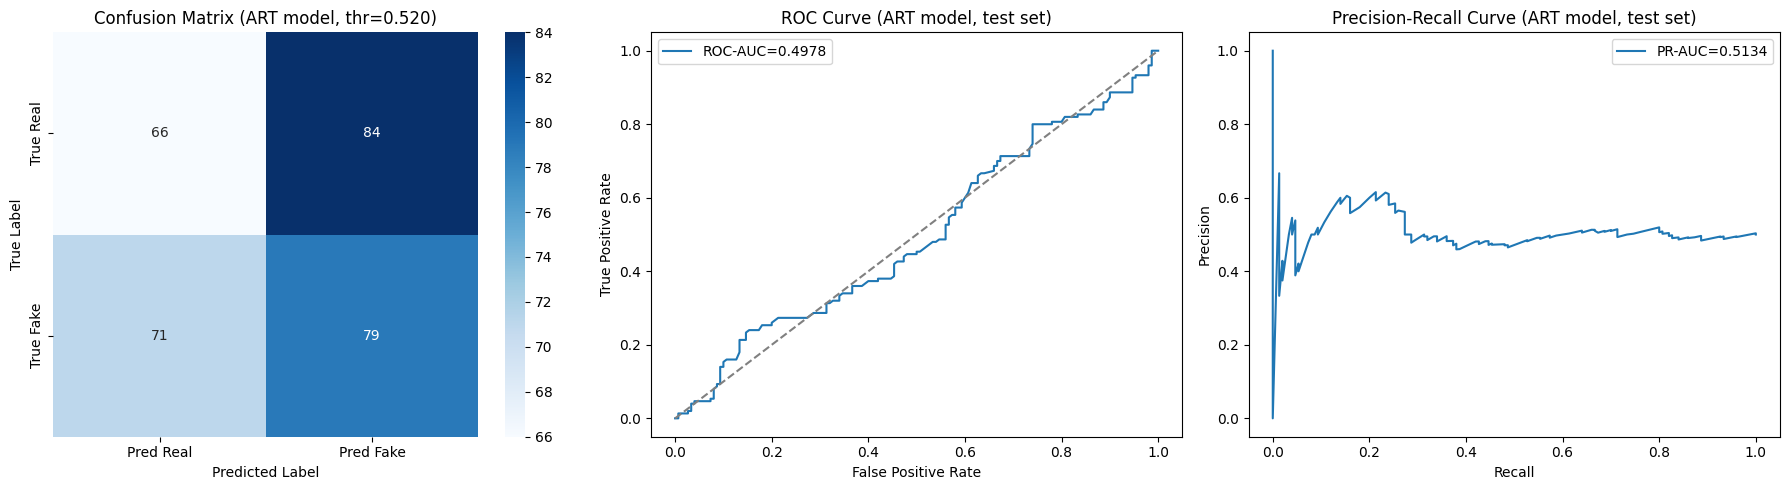

In [21]:
# ============================================================
# CELL 20: Confusion matrix / ROC / PR curves
# ============================================================
# Reuses the raw test predictions from Cell 13/15 (no repeated inference).

preds_selected = (art_test_probs >= selected_threshold).astype(int)
cm = confusion_matrix(art_test_labels, preds_selected)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Pred Real', 'Pred Fake'], yticklabels=['True Real', 'True Fake'])
axes[0].set_title(f"Confusion Matrix (ART model, thr={selected_threshold:.3f})")
axes[0].set_ylabel("True Label")
axes[0].set_xlabel("Predicted Label")

fpr, tpr, _ = roc_curve(art_test_labels, art_test_probs)
axes[1].plot(fpr, tpr, label=f"ROC-AUC={art_test_metrics_selected['roc_auc']:.4f}")
axes[1].plot([0, 1], [0, 1], '--', color='gray')
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve (ART model, test set)")
axes[1].legend()

precision_curve, recall_curve, _ = precision_recall_curve(art_test_labels, art_test_probs)
axes[2].plot(recall_curve, precision_curve, label=f"PR-AUC={art_test_metrics_selected['pr_auc']:.4f}")
axes[2].set_xlabel("Recall")
axes[2].set_ylabel("Precision")
axes[2].set_title("Precision-Recall Curve (ART model, test set)")
axes[2].legend()

plt.tight_layout()
plt.savefig("/kaggle/working/final_evaluation_curves.png", dpi=150)
plt.show()


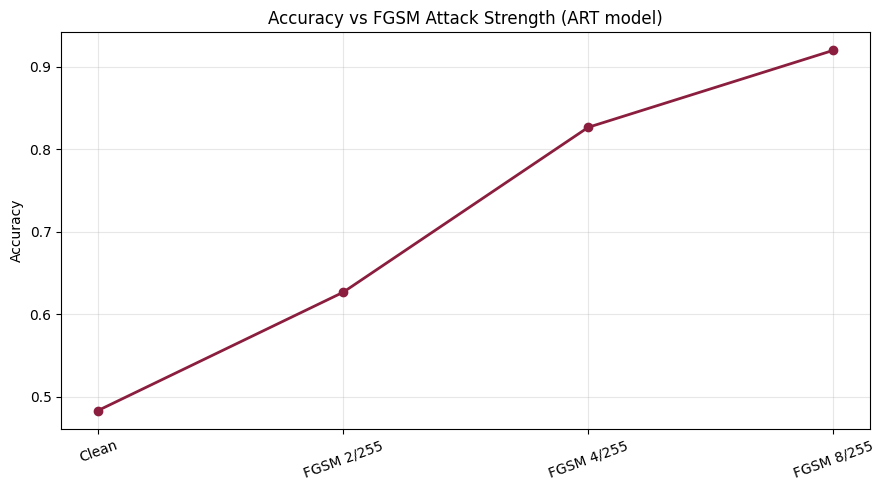

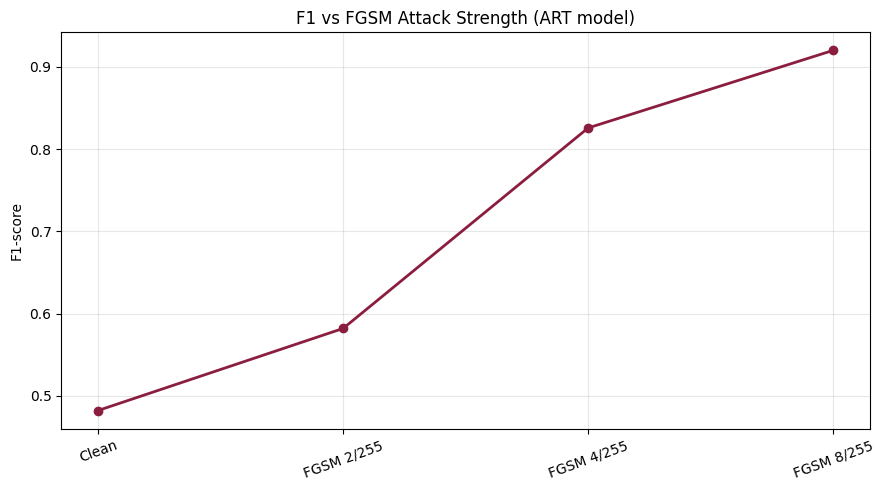

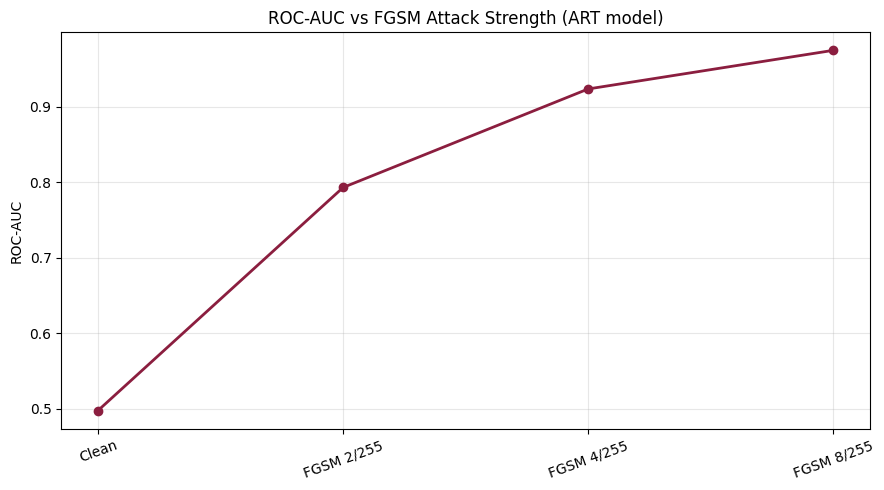

Saved robustness plots to /kaggle/working/.


In [22]:
# ============================================================
# CELL 21: Robustness plots
# ============================================================

labels_x = fgsm_df["Condition"].tolist()
x_positions = range(len(labels_x))


def plot_metric_vs_attack(metric_col, ylabel, title, out_path):
    plt.figure(figsize=(9, 5))
    plt.plot(x_positions, fgsm_df[metric_col], marker="o", linewidth=2, color="#8B1E3F")
    plt.xticks(list(x_positions), labels_x, rotation=20)
    plt.ylabel(ylabel)
    plt.title(title)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(out_path, dpi=150)
    plt.show()


plot_metric_vs_attack("accuracy", "Accuracy", "Accuracy vs FGSM Attack Strength (ART model)",
                       "/kaggle/working/robustness_accuracy.png")
plot_metric_vs_attack("f1", "F1-score", "F1 vs FGSM Attack Strength (ART model)",
                       "/kaggle/working/robustness_f1.png")
plot_metric_vs_attack("roc_auc", "ROC-AUC", "ROC-AUC vs FGSM Attack Strength (ART model)",
                       "/kaggle/working/robustness_auc.png")

print("Saved robustness plots to /kaggle/working/.")


True label               : real
Clean prediction         : fake (confidence 0.5046)
Adversarial prediction   : real (confidence 0.6475)


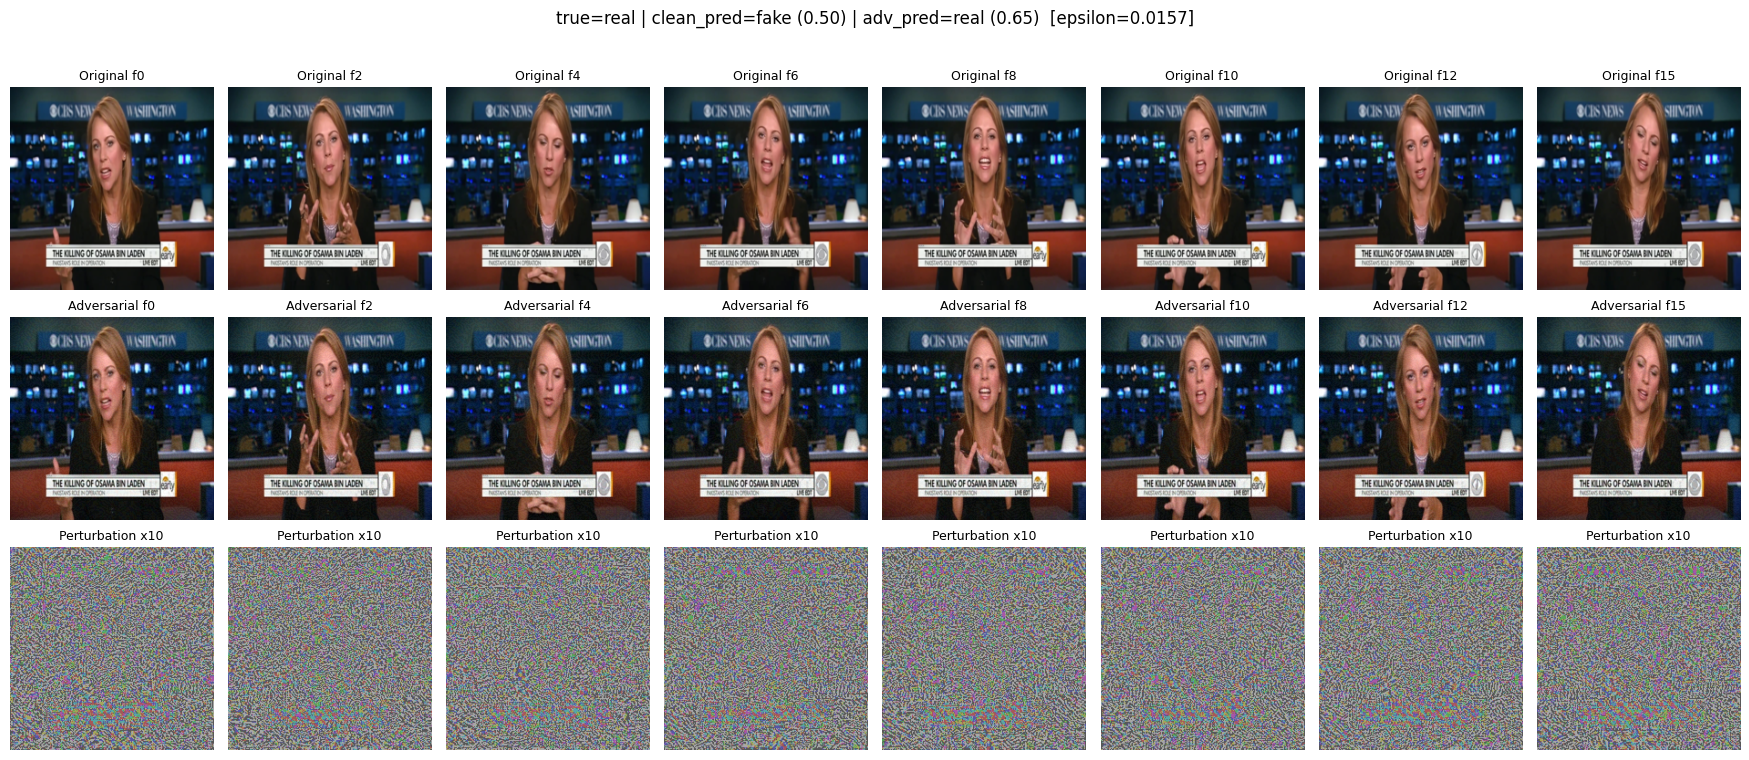

In [23]:
# ============================================================
# CELL 22: Adversarial example visualization
# ============================================================
# Original / Adversarial / Perturbation x10 for several frames of one test
# video, using the ART model. The amplified perturbation panel is for
# DISPLAY ONLY and is never fed back into the model.

NUM_FRAMES_TO_SHOW = 8

sample_video, sample_label = test_dataset[0]
sample_video = sample_video.unsqueeze(0).to(CONFIG["device"])           # [1, T, 3, 224, 224]
sample_label_tensor = sample_label.unsqueeze(0).to(CONFIG["device"])    # [1]

art_model.eval()

with torch.no_grad():
    clean_logits = art_model(sample_video)
    clean_prob_fake = torch.sigmoid(clean_logits).item()

adv_video = fgsm_attack(
    art_model, sample_video, sample_label_tensor,
    epsilon=CONFIG["adv_eval_epsilon"], criterion=criterion
)

with torch.no_grad():
    adv_logits = art_model(adv_video)
    adv_prob_fake = torch.sigmoid(adv_logits).item()

true_label_str = "fake" if int(sample_label.item()) == 1 else "real"
clean_pred_str = "fake" if clean_prob_fake >= 0.5 else "real"
adv_pred_str = "fake" if adv_prob_fake >= 0.5 else "real"
clean_conf = clean_prob_fake if clean_pred_str == "fake" else 1 - clean_prob_fake
adv_conf = adv_prob_fake if adv_pred_str == "fake" else 1 - adv_prob_fake

print(f"True label               : {true_label_str}")
print(f"Clean prediction         : {clean_pred_str} (confidence {clean_conf:.4f})")
print(f"Adversarial prediction   : {adv_pred_str} (confidence {adv_conf:.4f})")

mean = np.array(IMAGENET_MEAN)
std = np.array(IMAGENET_STD)

total_frames = sample_video.shape[1]
frame_indices = np.linspace(0, total_frames - 1, NUM_FRAMES_TO_SHOW, dtype=int)

fig, axes = plt.subplots(3, NUM_FRAMES_TO_SHOW, figsize=(2.2 * NUM_FRAMES_TO_SHOW, 7.5))
fig.suptitle(
    f"true={true_label_str} | clean_pred={clean_pred_str} ({clean_conf:.2f}) | "
    f"adv_pred={adv_pred_str} ({adv_conf:.2f})  [epsilon={CONFIG['adv_eval_epsilon']:.4f}]",
    fontsize=12, y=1.02
)

for i, f_idx in enumerate(frame_indices):
    clean_frame = sample_video[0, f_idx].detach().cpu().numpy().transpose(1, 2, 0)
    adv_frame = adv_video[0, f_idx].detach().cpu().numpy().transpose(1, 2, 0)

    clean_pixel = np.clip(std * clean_frame + mean, 0, 1)
    adv_pixel = np.clip(std * adv_frame + mean, 0, 1)

    perturbation = adv_pixel - clean_pixel
    perturbation_amplified = np.clip(perturbation * 10 + 0.5, 0, 1)

    axes[0, i].imshow(clean_pixel)
    axes[0, i].set_title(f"Original f{f_idx}", fontsize=9)
    axes[0, i].axis("off")

    axes[1, i].imshow(adv_pixel)
    axes[1, i].set_title(f"Adversarial f{f_idx}", fontsize=9)
    axes[1, i].axis("off")

    axes[2, i].imshow(perturbation_amplified)
    axes[2, i].set_title("Perturbation x10", fontsize=9)
    axes[2, i].axis("off")

plt.tight_layout()
plt.savefig("/kaggle/working/adversarial_example_visualization.png", dpi=150)
plt.show()


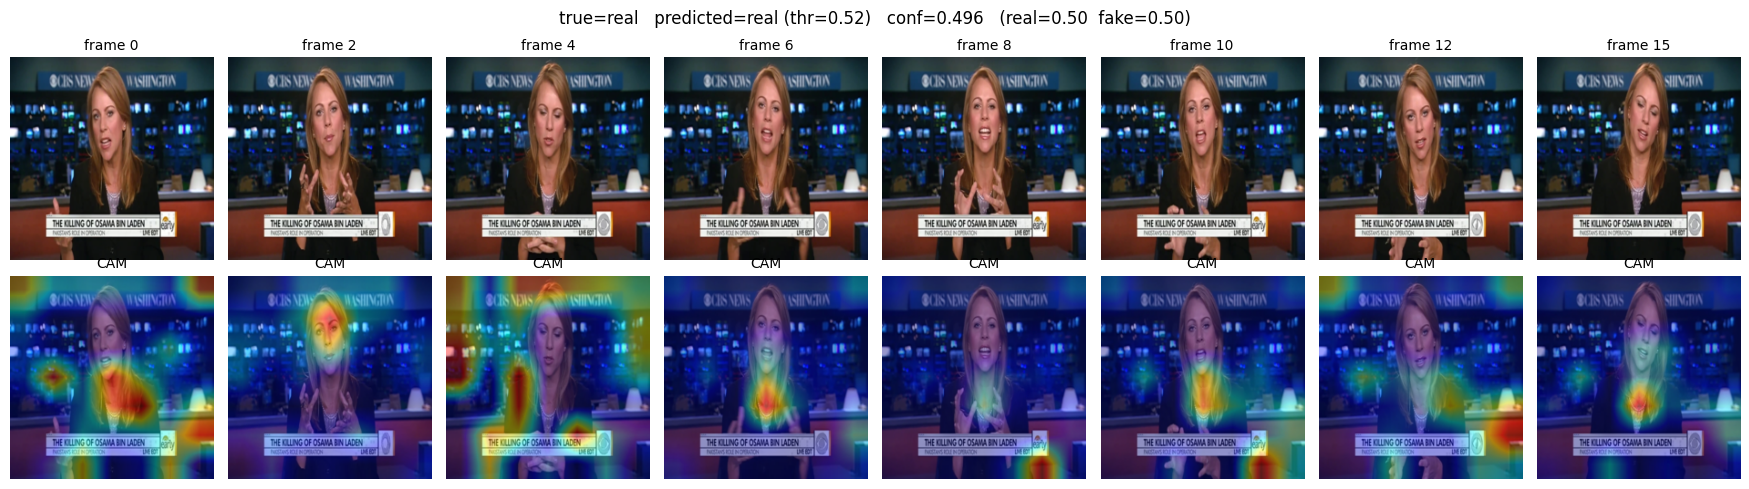

In [24]:
# ============================================================
# CELL 23: Grad-CAM
# ============================================================
# Same VideoGradCAM approach as the working notebook, adapted to reuse the
# `_prepare_model_for_attack` / `_restore_model_modes` helpers from Cell 7
# (instead of a blanket model.train()) so BatchNorm/Dropout stay frozen
# during the backward pass (deterministic, dropout-free CAMs) while the
# LSTM still gets cuDNN's training-mode backward kernel it requires.
# Target layer is unchanged: the final EfficientNet-B1 stage block.

class VideoGradCAM:
    def __init__(self, model, target_layer):
        self.model = model
        self.target_layer = target_layer
        self.gradients = None
        self.activations = None
        self.target_layer.register_forward_hook(self.save_activation)
        self.target_layer.register_full_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output.detach()

    def save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0].detach()

    def generate_heatmaps_all_frames(self, video_tensor):
        """video_tensor: [1, seq_len, 3, 224, 224]. Returns logits, fake
        probability, and per-frame heatmaps [seq_len, H, W]."""
        prev_modes = _prepare_model_for_attack(self.model)

        logits = self.model(video_tensor)
        prob = torch.sigmoid(logits).item()

        self.model.zero_grad()
        logits.backward()

        grads = self.gradients   # [seq_len, C, H, W]
        acts = self.activations  # [seq_len, C, H, W]

        weights = torch.mean(grads, dim=(2, 3), keepdim=True)
        cams = torch.sum(weights * acts, dim=1)
        cams = Fn.relu(cams)

        heatmaps = []
        for i in range(cams.size(0)):
            cam = cams[i]
            cam = cam - cam.min()
            cam = cam / (cam.max() + 1e-7)
            heatmaps.append(cam.cpu().numpy())

        _restore_model_modes(self.model, prev_modes)
        return logits, prob, np.array(heatmaps)


def visualize_gradcam_sequence(model, dataset, sample_idx=0, num_frames_to_display=8):
    target_layer = model.feature_extractor[0][-1]
    grad_cam = VideoGradCAM(model, target_layer)

    video_tensor, true_label_idx = dataset[sample_idx]
    true_label = "fake" if int(true_label_idx.item()) == 1 else "real"

    video_tensor_input = video_tensor.unsqueeze(0).to(CONFIG["device"])
    video_tensor_input.requires_grad = True

    _, fake_prob, heatmaps = grad_cam.generate_heatmaps_all_frames(video_tensor_input)

    real_prob = 1.0 - fake_prob
    pred_label = "fake" if fake_prob >= selected_threshold else "real"
    conf = fake_prob if pred_label == "fake" else real_prob

    total_seq_len = video_tensor.size(0)
    frame_indices = np.linspace(0, total_seq_len - 1, num_frames_to_display, dtype=int)

    mean = np.array(IMAGENET_MEAN)
    std = np.array(IMAGENET_STD)

    fig, axes = plt.subplots(2, num_frames_to_display, figsize=(2.2 * num_frames_to_display, 5))
    fig.suptitle(
        f"true={true_label}   predicted={pred_label} (thr={selected_threshold:.2f})   "
        f"conf={conf:.3f}   (real={real_prob:.2f}  fake={fake_prob:.2f})",
        fontsize=12, y=0.98
    )

    for i, f_idx in enumerate(frame_indices):
        src_frame = video_tensor[f_idx].detach().cpu().numpy().transpose(1, 2, 0)
        src_frame = std * src_frame + mean
        src_frame = np.clip(src_frame, 0, 1)
        src_frame_uint8 = (src_frame * 255).astype(np.uint8)

        heatmap_resized = cv2.resize(heatmaps[f_idx], (CONFIG["img_size"], CONFIG["img_size"]))
        heatmap_color = cv2.applyColorMap(np.uint8(255 * heatmap_resized), cv2.COLORMAP_JET)
        heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)

        overlay = cv2.addWeighted(src_frame_uint8, 0.6, heatmap_color, 0.4, 0)

        axes[0, i].imshow(src_frame)
        axes[0, i].set_title(f"frame {f_idx}", fontsize=10)
        axes[0, i].axis('off')

        axes[1, i].imshow(overlay)
        axes[1, i].set_title("CAM", fontsize=10)
        axes[1, i].axis('off')

    plt.tight_layout()
    plt.savefig("/kaggle/working/gradcam_visualization.png", dpi=150)
    plt.show()


# art_model already holds the best ART checkpoint (loaded in Cell 12).
visualize_gradcam_sequence(art_model, test_dataset, sample_idx=0, num_frames_to_display=8)


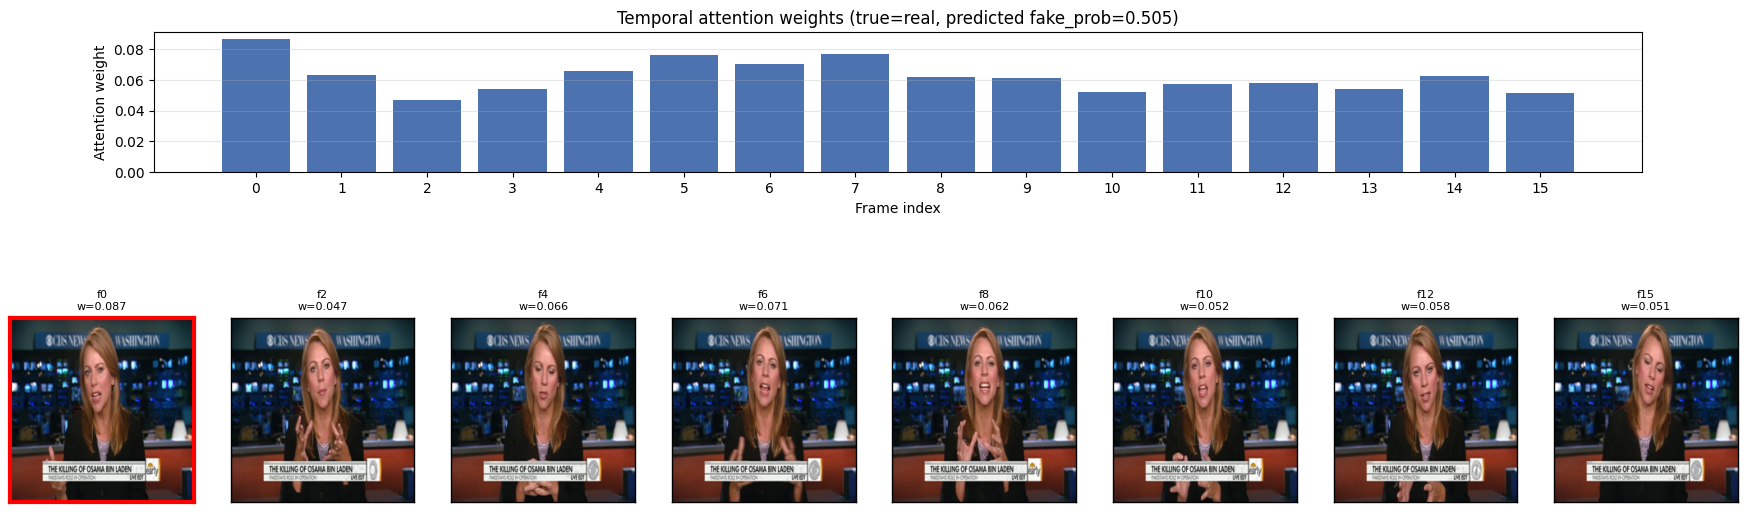

Most-attended frame: 0 (weight=0.0869)


In [25]:
# ============================================================
# CELL 24: Temporal attention visualization
# ============================================================
# Only meaningful when CONFIG['use_temporal_attention'] is True. Shows the
# learned per-frame attention weight (from the ART model's temporal
# attention pooling layer) alongside the corresponding frames, giving a
# temporal explanation to complement Grad-CAM's spatial explanation.

if not CONFIG["use_temporal_attention"]:
    print("CONFIG['use_temporal_attention'] is False (mean pooling in use) -- "
          "no attention weights to visualize in this run.")
else:
    sample_video, sample_label = test_dataset[0]
    video_input = sample_video.unsqueeze(0).to(CONFIG["device"])  # [1, T, 3, 224, 224]
    true_label_str = "fake" if int(sample_label.item()) == 1 else "real"

    art_model.eval()
    with torch.no_grad():
        logits = art_model(video_input)
        prob_fake = torch.sigmoid(logits).item()

    attn_weights = art_model.last_attention_weights[0].detach().cpu().numpy()  # [T]
    seq_len = len(attn_weights)

    mean = np.array(IMAGENET_MEAN)
    std = np.array(IMAGENET_STD)

    fig, axes = plt.subplots(2, 1, figsize=(max(12, seq_len * 1.2), 6),
                              gridspec_kw={"height_ratios": [1, 2]})

    # ---- Top: attention weight bar chart ----
    axes[0].bar(range(seq_len), attn_weights, color="#4C72B0")
    axes[0].set_xticks(range(seq_len))
    axes[0].set_xlabel("Frame index")
    axes[0].set_ylabel("Attention weight")
    axes[0].set_title(
        f"Temporal attention weights (true={true_label_str}, "
        f"predicted fake_prob={prob_fake:.3f})"
    )
    axes[0].grid(axis="y", alpha=0.3)

    # ---- Bottom: the actual frames, most-attended frame highlighted ----
    top_frame_idx = int(np.argmax(attn_weights))
    n_show = min(seq_len, 8)
    show_indices = np.linspace(0, seq_len - 1, n_show, dtype=int)

    axes[1].axis("off")
    inner = fig.add_gridspec(1, n_show, left=0.05, right=0.95, top=0.45, bottom=0.05)
    for col, f_idx in enumerate(show_indices):
        ax = fig.add_subplot(inner[0, col])
        frame = sample_video[f_idx].numpy().transpose(1, 2, 0)
        frame = np.clip(std * frame + mean, 0, 1)
        ax.imshow(frame)
        border_color = "red" if f_idx == top_frame_idx else "black"
        for spine in ax.spines.values():
            spine.set_edgecolor(border_color)
            spine.set_linewidth(3 if f_idx == top_frame_idx else 1)
        ax.set_xticks([])
        ax.set_yticks([])
        ax.set_title(f"f{f_idx}\nw={attn_weights[f_idx]:.3f}", fontsize=8)

    plt.savefig("/kaggle/working/temporal_attention_visualization.png", dpi=150, bbox_inches="tight")
    plt.show()

    print(f"Most-attended frame: {top_frame_idx} (weight={attn_weights[top_frame_idx]:.4f})")


In [26]:
# ============================================================
# CELL 25: Final research summary
# ============================================================
# Every number below is read from variables computed earlier in this
# notebook run -- nothing here is hard-coded, and the conclusion is
# generated conditionally from the measured retention/accuracy numbers.

print("=" * 70)
print("FINAL RESEARCH SUMMARY")
print("=" * 70)

print(f"""
1. DATASET
   FaceForensics++ C23, {len(extracted_records)} usable videos total
   (real={n_real}, fake={n_fake}). Group-aware split by source identity:
     Train: {len(train_records)} videos
     Val  : {len(val_records)} videos (class-balanced)
     Test : {len(test_records)} videos (class-balanced)
   No source-identity group appears in more than one split (verified in Cell 3).

2. MODEL ARCHITECTURE
   EfficientNet-B1 (ImageNet-pretrained) -> projection (1280->512) ->
   {'Bi' if CONFIG['lstm_bidirectional'] else ''}LSTM(hidden={CONFIG['lstm_hidden_size']}, layers={CONFIG['lstm_num_layers']}) ->
   {'learnable temporal attention pooling' if CONFIG['use_temporal_attention'] else 'mean pooling'} -> classifier
   Total parameters: {total_params:,}

3. TRAINING STRATEGY
   Staged transfer learning: Phase 1 ({CONFIG['phase1_epochs']} epochs, backbone frozen) ->
   Phase 2 ({CONFIG['phase2_epochs']} epochs, last {CONFIG['unfreeze_last_n_blocks']} backbone blocks unfrozen)
   Discriminative LRs: backbone={CONFIG['backbone_lr']}, head={CONFIG['head_lr']}
   AdamW, weight_decay={CONFIG['weight_decay']}, gradient clip norm={CONFIG['grad_clip_norm']}
   ReduceLROnPlateau (factor={CONFIG['scheduler_factor']}, patience={CONFIG['scheduler_patience']}) on validation F1
   Early stopping patience={CONFIG['early_stopping_patience']} epochs (validation F1)
   Class-weighted BCEWithLogitsLoss (pos_weight from TRAIN labels only): {CONFIG['use_class_weight']}

4. ART STRATEGY
   FGSM adversarial training, epsilon={CONFIG['epsilon']:.4f} (px)
   Combined loss = {CONFIG['clean_loss_weight']} * clean_loss + {CONFIG['adv_loss_weight']} * adversarial_loss
   PGD used for evaluation only (never for training)

5. BEST VALIDATION METRICS (model selection -- never test-derived)
   Clean-trained model: best validation F1 = {clean_best_val_f1:.4f}
   ART-trained model  : best validation F1 = {art_best_val_f1:.4f}

6. SELECTED CLASSIFICATION THRESHOLD (chosen on validation, frozen for test)
   Clean-trained model threshold: {clean_selected_threshold:.3f}
   ART-trained model threshold  : {selected_threshold:.3f}

7. FINAL CLEAN TEST METRICS (ART model, at its selected threshold)
   Accuracy={art_test_metrics_selected['accuracy']:.4f}  F1={art_test_metrics_selected['f1']:.4f}
   ROC-AUC={art_test_metrics_selected['roc_auc']:.4f}  PR-AUC={art_test_metrics_selected['pr_auc']:.4f}
   Balanced Accuracy={art_test_metrics_selected['balanced_accuracy']:.4f}
""")

print("8. FGSM ROBUSTNESS (ART model)")
print(fgsm_df[["Condition", "accuracy", "f1", "roc_auc", "Retention %"]].to_string(index=False))

print("\n9. PGD ROBUSTNESS (ART model)")
print(pgd_df[["Condition", "accuracy", "f1", "roc_auc", "Retention %"]].to_string(index=False))

print("\n10. CLEAN-TRAINED vs ART-TRAINED COMPARISON")
print(comparison_df.to_string(index=False))

# ---- Data-driven conclusion ----
art_clean_acc = _val("ART-trained", "Clean", "accuracy")
clean_clean_acc = _val("Clean-trained", "Clean", "accuracy")

art_fgsm8_ret = _val("ART-trained", "FGSM 8/255", "accuracy") / max(art_clean_acc, 1e-9) * 100
clean_fgsm8_ret = _val("Clean-trained", "FGSM 8/255", "accuracy") / max(clean_clean_acc, 1e-9) * 100
art_pgd5_ret = _val("ART-trained", "PGD-5 4/255", "accuracy") / max(art_clean_acc, 1e-9) * 100
clean_pgd5_ret = _val("Clean-trained", "PGD-5 4/255", "accuracy") / max(clean_clean_acc, 1e-9) * 100

conclusion_lines = []
if art_fgsm8_ret > clean_fgsm8_ret and art_pgd5_ret > clean_pgd5_ret:
    conclusion_lines.append(
        f"Measured results show the ART-trained model retains more accuracy under both FGSM 8/255 "
        f"({art_fgsm8_ret:.1f}% vs {clean_fgsm8_ret:.1f}%) and PGD-5 4/255 "
        f"({art_pgd5_ret:.1f}% vs {clean_pgd5_ret:.1f}%) compared to the clean-trained model -- "
        f"adversarial training improved robustness retention in this run."
    )
elif art_fgsm8_ret > clean_fgsm8_ret or art_pgd5_ret > clean_pgd5_ret:
    conclusion_lines.append(
        "Measured results show a MIXED robustness outcome: ART improved retention under one attack "
        "condition but not the other, based on this run's numbers -- not a uniform improvement."
    )
else:
    conclusion_lines.append(
        "Measured results do NOT show a robustness improvement from ART in this run "
        "(retention was not higher under either FGSM 8/255 or PGD-5 4/255 vs the clean-trained model)."
    )

clean_acc_cost = clean_clean_acc - art_clean_acc
if clean_acc_cost > 0.02:
    conclusion_lines.append(
        f"This came with a clean-accuracy cost of {clean_acc_cost * 100:.1f} percentage points "
        f"({clean_clean_acc:.4f} -> {art_clean_acc:.4f})."
    )
else:
    conclusion_lines.append(
        f"Clean accuracy was largely preserved (Clean-trained={clean_clean_acc:.4f} vs "
        f"ART-trained={art_clean_acc:.4f})."
    )

print("\n11. MAIN CONCLUSION")
for line in conclusion_lines:
    print("   " + line)

# ---- Persist run artifacts ----
def _json_safe(v):
    if isinstance(v, torch.device):
        return str(v)
    return v


run_config_serializable = {k: _json_safe(v) for k, v in CONFIG.items()}

run_summary = {
    "config": run_config_serializable,
    "best_val_f1": {"clean": clean_best_val_f1, "art": art_best_val_f1},
    "selected_threshold": {"clean": clean_selected_threshold, "art": selected_threshold},
    "final_test_metrics_art": art_test_metrics_selected,
    "comparison_table": comparison_df.to_dict(orient="records"),
}

with open(CONFIG["save_best_metrics_path"], "w") as f:
    json.dump(run_summary, f, indent=2, default=str)

with open(CONFIG["save_run_config_path"], "w") as f:
    json.dump(run_config_serializable, f, indent=2, default=str)

print(f"\nSaved final metrics to {CONFIG['save_best_metrics_path']}")
print(f"Saved run configuration to {CONFIG['save_run_config_path']}")
print("=" * 70)


FINAL RESEARCH SUMMARY

1. DATASET
   FaceForensics++ C23, 6000 usable videos total
   (real=1000, fake=5000). Group-aware split by source identity:
     Train: 4200 videos
     Val  : 300 videos (class-balanced)
     Test : 300 videos (class-balanced)
   No source-identity group appears in more than one split (verified in Cell 3).

2. MODEL ARCHITECTURE
   EfficientNet-B1 (ImageNet-pretrained) -> projection (1280->512) ->
   BiLSTM(hidden=512, layers=2) ->
   learnable temporal attention pooling -> classifier
   Total parameters: 18,459,170

3. TRAINING STRATEGY
   Staged transfer learning: Phase 1 (3 epochs, backbone frozen) ->
   Phase 2 (4 epochs, last 3 backbone blocks unfrozen)
   Discriminative LRs: backbone=1e-05, head=0.0001
   AdamW, weight_decay=0.01, gradient clip norm=5.0
   ReduceLROnPlateau (factor=0.5, patience=2) on validation F1
   Early stopping patience=4 epochs (validation F1)
   Class-weighted BCEWithLogitsLoss (pos_weight from TRAIN labels only): True

4. ART STR